# <div dir="rtl">مشروع كشف الصور المولّدة بالذكاء الاصطناعي</div>
<div dir="rtl">

**SVM + Random Forest + CNN (ResNet50)** على CIFAKE و GenImage.


## <div dir="rtl">الخطوة 1: ربط Google Drive وتجهيز المسارات</div>


In [10]:
from google.colab import drive
drive.mount('/content/drive')

import os
PROJECT = '/content/drive/MyDrive/AI_Image_Detection'   # مكان المشروع في درايف
os.makedirs(PROJECT, exist_ok=True)
os.environ['AIID_CACHE_DIR'] = '/content/cache'          # الصور الجاهزة (على جهاز Colab نفسه = أسرع)
os.environ['AIID_CIFAKE_ROOT'] = '/content/data/CIFAKE'
os.environ['AIID_GENIMAGE_ROOT'] = '/content/data/GenImage'
%cd {PROJECT}
print('Project folder:', PROJECT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/AI_Image_Detection
Project folder: /content/drive/MyDrive/AI_Image_Detection


In [11]:
t = open('config.py', encoding='utf-8').read()
open('config.py', 'w', encoding='utf-8').write(t.replace('GenImage 6 generators', 'GenImage 5 generators'))
!python -m evaluation.evaluate_robustness
!python -m evaluation.report_tables

model experiment condition  accuracy  roc_auc  delta_accuracy
  cnn       exp1     clean    0.9590   0.9930          0.0000
  cnn       exp1    jpeg90    0.9568   0.9927         -0.0022
  cnn       exp1    jpeg70    0.9530   0.9912         -0.0060
  cnn       exp1    jpeg50    0.9472   0.9898         -0.0117
  cnn       exp1 resize112    0.9562   0.9929         -0.0027
  cnn       exp1  resize56    0.9558   0.9922         -0.0032
  cnn       exp1  noise001    0.9032   0.9646         -0.0557
  cnn       exp1  noise003    0.7542   0.9262         -0.2047
  cnn       exp1  noise005    0.6860   0.9062         -0.2730
   rf       exp1     clean    0.8892   0.9593          0.0000
   rf       exp1    jpeg90    0.8922   0.9594          0.0030
   rf       exp1    jpeg70    0.8888   0.9589         -0.0005
   rf       exp1    jpeg50    0.8845   0.9572         -0.0048
   rf       exp1 resize112    0.8910   0.9590          0.0018
   rf       exp1  resize56    0.8880   0.9575         -0.0012
   rf   

In [12]:
!grep -n "generators ->" results/final_results_report.md

33:## Experiment 2: GenImage 5 generators -> BigGAN + Midjourney


In [14]:
import re, glob
n = 0
for p in glob.glob('**/*.py', recursive=True):
    t = open(p, encoding='utf-8').read()
    new = re.sub(r'Student \d - (\w)', lambda m: m.group(1).upper(), t)
    new = re.sub(r' \(Students? \d[^)]*\)', '', new)
    if new != t:
        open(p, 'w', encoding='utf-8').write(new); n += 1
print(f'cleaned {n} files')

cleaned 0 files


In [15]:
!grep -rn "Student" --include=*.py . | wc -l

0


## <div dir="rtl">الخطوة 2: كتابة ملفات المشروع</div>
<div dir="rtl">


In [3]:
!mkdir -p preprocessing eda features models training evaluation checkpoints/svm checkpoints/rf checkpoints/cnn results/predictions results/tables results/figures results/robustness logs data/manifests
for d in ['preprocessing', 'eda', 'features', 'models', 'training', 'evaluation']:
    open(f'{d}/__init__.py', 'w').write('"""Package marker."""\n')
print('folders ready')

folders ready


In [35]:
%%writefile config.py
"""
Central configuration for the AI-Generated Image Detection project.

EVERY shared setting lives here. Do not change a value without team agreement,
and record the change in README.md ("Decision log").

Paths can be overridden with environment variables (used by the Colab notebook):
    AIID_CIFAKE_ROOT, AIID_GENIMAGE_ROOT, AIID_CACHE_DIR, AIID_FEATURE_DIR
"""
import os
from pathlib import Path

# ---------------------------------------------------------------------------
# Paths (all relative to the project root unless overridden)
# ---------------------------------------------------------------------------
PROJECT_ROOT = Path(__file__).resolve().parent


def _path_from_env(var_name, default):
    value = os.environ.get(var_name)
    return Path(value).expanduser() if value else Path(default)


DATA_DIR = PROJECT_ROOT / "data"
CIFAKE_ROOT = _path_from_env("AIID_CIFAKE_ROOT", DATA_DIR / "CIFAKE")
GENIMAGE_ROOT = _path_from_env("AIID_GENIMAGE_ROOT", DATA_DIR / "GenImage")
MANIFEST_DIR = DATA_DIR / "manifests"
# Preprocessed 224x224 uint8 image arrays (.npy). Large -> keep on local disk.
CACHE_DIR = _path_from_env("AIID_CACHE_DIR", DATA_DIR / "cache")
FEATURE_DIR = _path_from_env("AIID_FEATURE_DIR", PROJECT_ROOT / "features" / "saved")

CHECKPOINT_DIR = PROJECT_ROOT / "checkpoints"
RESULTS_DIR = PROJECT_ROOT / "results"
PRED_DIR = RESULTS_DIR / "predictions"
TABLE_DIR = RESULTS_DIR / "tables"
FIGURE_DIR = RESULTS_DIR / "figures"
ROBUSTNESS_DIR = RESULTS_DIR / "robustness"
LOG_DIR = PROJECT_ROOT / "logs"
RUN_LOG = LOG_DIR / "run_log.csv"

OUTPUT_DIRS = [
    MANIFEST_DIR, CACHE_DIR, FEATURE_DIR,
    CHECKPOINT_DIR / "svm", CHECKPOINT_DIR / "rf", CHECKPOINT_DIR / "cnn",
    PRED_DIR, TABLE_DIR, FIGURE_DIR, ROBUSTNESS_DIR, LOG_DIR,
]

# ---------------------------------------------------------------------------
# Agreed global settings
# ---------------------------------------------------------------------------
SEED = 42
LABEL_REAL = 0
LABEL_AI = 1
CLASS_NAMES = {LABEL_REAL: "Real", LABEL_AI: "AI-generated"}
POSITIVE_CLASS = LABEL_AI
THRESHOLD = 0.5

IMAGE_SIZE = 224
COLOR_MODE = "RGB"
RESIZE_INTERPOLATION = "bicubic"
RESIZE_POLICY = "shorter side -> 224 (bicubic), then center crop 224x224"
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}

BATCH_SIZE = 32
NUM_WORKERS = 2  # Colab has 2 CPU cores

BACKBONE = "resnet50"
PRETRAINED_WEIGHTS = "IMAGENET1K_V1"
FEATURE_DIM = 2048

# ---------------------------------------------------------------------------
# Datasets and sample counts (decided by the team: 20,000 images per dataset)
# ---------------------------------------------------------------------------
CIFAKE = "CIFAKE"
GENIMAGE = "GenImage"
DATASETS = [CIFAKE, GENIMAGE]
SPLITS = ["train", "val", "test"]

# CIFAKE: images PER CLASS. Keys are the OFFICIAL CIFAKE split folders,
# values are the project splits taken from them (train/val never touch official test).
CIFAKE_PER_CLASS = {
    "train": {"train": 7000, "val": 1000},
    "test": {"test": 2000},
}
CIFAKE_JPEG_QUALITY = None  # CIFAKE is used as provided

# GenImage generators
GENIMAGE_TRAIN_GENERATORS = ["ADM", "GLIDE", "SD15", "VQDM", "Wukong"]
GENIMAGE_TEST_GENERATORS = ["BigGAN", "Midjourney"]  # held-out: TEST ONLY
GENIMAGE_ALL_GENERATORS = GENIMAGE_TRAIN_GENERATORS + GENIMAGE_TEST_GENERATORS

# Images PER CLASS per generator (2,500 images per generator in total)
GENIMAGE_PER_CLASS_TRAIN_GEN = {"train": 1000, "val": 250}
GENIMAGE_PER_CLASS_TEST_GEN = {"test": 1250}

# Every selected GenImage image (real AND AI) is re-encoded as JPEG Q95 BEFORE
# resizing, so that the file format (JPEG real vs PNG fake) cannot be a shortcut.
GENIMAGE_JPEG_QUALITY = 95

# Keywords used to recognise generator folders (case-insensitive substring match).
# Covers the official names, e.g. "imagenet_ai_0419_sdv4", "imagenet_midjourney".
GENIMAGE_FOLDER_KEYWORDS = {
    "ADM": ["adm"],
    "GLIDE": ["glide"],
    "SD14": ["sdv4", "sd14", "sd_1_4", "sd1.4", "sdv1.4", "sdv14", "stable_diffusion_v_1_4"],
    "SD15": ["sdv5", "sd15", "sd_1_5", "sd1.5", "sdv1.5", "sdv15", "stable_diffusion_v_1_5"],
    "VQDM": ["vqdm"],
    "Wukong": ["wukong"],
    "BigGAN": ["biggan"],
    "Midjourney": ["midjourney"],
}
GENIMAGE_AI_DIR_NAMES = ("ai", "fake")
GENIMAGE_REAL_DIR_NAMES = ("nature", "real")

# Perceptual-hash near-duplicate threshold (Hamming distance on 64-bit pHash).
PHASH_MAX_DISTANCE = 2


def expected_counts(dataset):
    """Return {split: {label: count}} expected for a dataset."""
    out = {s: {LABEL_REAL: 0, LABEL_AI: 0} for s in SPLITS}
    if dataset == CIFAKE:
        for _, project_splits in CIFAKE_PER_CLASS.items():
            for split, n in project_splits.items():
                out[split][LABEL_REAL] += n
                out[split][LABEL_AI] += n
    else:
        for gen in GENIMAGE_ALL_GENERATORS:
            per = GENIMAGE_PER_CLASS_TEST_GEN if gen in GENIMAGE_TEST_GENERATORS else GENIMAGE_PER_CLASS_TRAIN_GEN
            for split, n in per.items():
                out[split][LABEL_REAL] += n
                out[split][LABEL_AI] += n
    return out


# ---------------------------------------------------------------------------
# Image conditions (robustness transformations + the 32x32 condition).
# All are applied to the cached 224x224 RGB image, BEFORE ImageNet normalisation.
# ---------------------------------------------------------------------------
CONDITIONS = {
    "clean": {"type": "none", "label": "Clean baseline", "params": "none"},
    "jpeg90": {"type": "jpeg", "quality": 90, "label": "JPEG Q90", "params": "quality=90"},
    "jpeg70": {"type": "jpeg", "quality": 70, "label": "JPEG Q70", "params": "quality=70"},
    "jpeg50": {"type": "jpeg", "quality": 50, "label": "JPEG Q50", "params": "quality=50"},
    "resize112": {"type": "resize", "size": 112, "label": "Resize 112", "params": "224->112->224 bicubic"},
    "resize56": {"type": "resize", "size": 56, "label": "Resize 56", "params": "224->56->224 bicubic"},
    "noise001": {"type": "noise", "std": 0.01, "label": "Noise 0.01", "params": "sigma=0.01 on [0,1], clipped"},
    "noise003": {"type": "noise", "std": 0.03, "label": "Noise 0.03", "params": "sigma=0.03 on [0,1], clipped"},
    "noise005": {"type": "noise", "std": 0.05, "label": "Noise 0.05", "params": "sigma=0.05 on [0,1], clipped"},
    # Additional resolution experiment (train AND test under this condition)
    "res32": {"type": "resize", "size": 32, "label": "32x32 resolution", "params": "224->32->224 bicubic"},
}
ROBUSTNESS_CONDITIONS = ["clean", "jpeg90", "jpeg70", "jpeg50", "resize112", "resize56",
                         "noise001", "noise003", "noise005"]

# ---------------------------------------------------------------------------
# Models, training sets and experiments
# ---------------------------------------------------------------------------
MODELS = ["svm", "rf", "cnn"]
MODEL_DISPLAY = {"svm": "SVM", "rf": "Random Forest", "cnn": "CNN (ResNet50)"}

# A "model tag" = which data a model is trained/validated on.
MODEL_TAGS = {
    "cifake": {"dataset": CIFAKE, "condition": "clean"},
    "genimage": {"dataset": GENIMAGE, "condition": "clean"},
    "res32": {"dataset": GENIMAGE, "condition": "res32"},
}

EXPERIMENTS = {
    "exp1": {"title": "Experiment 1: CIFAKE -> CIFAKE", "model_tag": "cifake", "test_dataset": CIFAKE},
    "exp2": {"title": "Experiment 2: GenImage 6 generators -> BigGAN + Midjourney", "model_tag": "genimage", "test_dataset": GENIMAGE},
    "exp3": {"title": "Experiment 3: CIFAKE model -> GenImage held-out test (no retraining)", "model_tag": "cifake", "test_dataset": GENIMAGE},
    "res32": {"title": "Additional: 32x32 resolution (GenImage, train+test at 32x32)", "model_tag": "res32", "test_dataset": GENIMAGE},
}
ROBUSTNESS_EXPERIMENTS = ["exp1", "exp2"]


def build_prediction_plan():
    """Every (experiment, condition) a model must be evaluated on."""
    plan = []
    for exp in ROBUSTNESS_EXPERIMENTS:
        for cond in ROBUSTNESS_CONDITIONS:
            plan.append({"experiment": exp, "model_tag": EXPERIMENTS[exp]["model_tag"],
                         "dataset": EXPERIMENTS[exp]["test_dataset"], "split": "test", "condition": cond})
    plan.append({"experiment": "exp3", "model_tag": "cifake", "dataset": GENIMAGE, "split": "test", "condition": "clean"})
    plan.append({"experiment": "res32", "model_tag": "res32", "dataset": GENIMAGE, "split": "test", "condition": "res32"})
    return plan


PREDICTION_PLAN = build_prediction_plan()


def build_feature_sets():
    """All (dataset, split, condition) feature files needed by SVM and RF."""
    sets = []
    for tag in MODEL_TAGS.values():
        for split in ("train", "val"):
            sets.append((tag["dataset"], split, tag["condition"]))
    for entry in PREDICTION_PLAN:
        sets.append((entry["dataset"], entry["split"], entry["condition"]))
    return list(dict.fromkeys(sets))  # unique, order preserved


FEATURE_SETS = build_feature_sets()

# ---------------------------------------------------------------------------
# SVM / Random Forest (selected on the VALIDATION split only)
# ---------------------------------------------------------------------------
SELECTION_METRIC = "roc_auc"  # validation ROC-AUC, ties broken by validation accuracy
SVM_PARAM_GRID = [
    {"kernel": "rbf", "C": 1.0, "gamma": "scale"},
    {"kernel": "rbf", "C": 10.0, "gamma": "scale"},
    {"kernel": "linear", "C": 0.01},
    {"kernel": "linear", "C": 0.1},
]
SVM_CACHE_MB = 2000
RF_PARAM_GRID = [
    {"n_estimators": n, "max_depth": d}
    for n in (200, 500) for d in (None, 20)
]
RF_MAX_FEATURES = "sqrt"

# ---------------------------------------------------------------------------
# CNN (ResNet50 transfer learning)
# ---------------------------------------------------------------------------
CNN_DROPOUT = 0.3
CNN_OPTIMIZER = "Adam"
CNN_LOSS = "BCEWithLogitsLoss (= sigmoid + binary cross-entropy, numerically stable)"
CNN_STAGE1_LR = 1e-4
CNN_STAGE2_LR = 1e-5
CNN_STAGE1_MAX_EPOCHS = 5    # frozen backbone
CNN_STAGE2_MAX_EPOCHS = 15   # layer4 unfrozen  -> 20 epochs maximum in total
CNN_PATIENCE = 5             # early stopping on validation loss (per stage)
CNN_HFLIP = True             # only augmentation: random horizontal flip (train split only)
CNN_USE_AMP = True           # mixed precision on CUDA only

Overwriting config.py


In [36]:
!grep "GENIMAGE_TRAIN_GENERATORS =" config.py

GENIMAGE_TRAIN_GENERATORS = ["ADM", "GLIDE", "SD15", "VQDM", "Wukong"]


In [5]:
%%writefile utils.py
"""Shared helpers: seeding, device selection, directories, run logging."""
import csv
import json
import os
import platform
import random
import time
from datetime import datetime
from pathlib import Path

import numpy as np

import config


def set_seed(seed=config.SEED, deterministic=True):
    """Seed Python, NumPy and PyTorch.

    Limitation: some CUDA kernels are not bit-for-bit deterministic, so CNN
    results on GPU can differ very slightly between runs.
    """
    random.seed(seed)
    np.random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
        if deterministic:
            torch.backends.cudnn.deterministic = True
            torch.backends.cudnn.benchmark = False
    except ImportError:
        pass


def get_device():
    """CUDA if available, otherwise CPU (no hard CUDA assumption)."""
    import torch
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def seed_worker(worker_id):
    """DataLoader worker seeding (keeps random flips reproducible)."""
    import torch
    worker_seed = torch.initial_seed() % 2 ** 32
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_generator(seed=config.SEED):
    import torch
    g = torch.Generator()
    g.manual_seed(seed)
    return g


def ensure_dirs():
    for d in config.OUTPUT_DIRS:
        Path(d).mkdir(parents=True, exist_ok=True)


def log_run(component, action, status="ok", **details):
    """Append one row to logs/run_log.csv."""
    ensure_dirs()
    path = config.RUN_LOG
    is_new = not path.exists()
    with open(path, "a", newline="", encoding="utf-8") as f:
        writer = csv.writer(f)
        if is_new:
            writer.writerow(["timestamp", "component", "action", "status", "details"])
        writer.writerow([datetime.now().isoformat(timespec="seconds"), component, action, status,
                         json.dumps(details, default=str, ensure_ascii=False)])


def save_json(obj, path):
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, default=str, ensure_ascii=False)


def environment_info():
    info = {"python": platform.python_version(), "platform": platform.platform(), "numpy": np.__version__}
    for name in ["torch", "torchvision", "sklearn", "pandas", "PIL", "imagehash", "matplotlib"]:
        try:
            module = __import__(name)
            info[name] = getattr(module, "__version__", "unknown")
        except ImportError:
            info[name] = "not installed"
    try:
        import torch
        info["cuda_available"] = torch.cuda.is_available()
        info["gpu"] = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
    except ImportError:
        pass
    return info


class Timer:
    """Usage:  with Timer() as t: ...;  t.seconds"""

    def __enter__(self):
        self.start = time.time()
        return self

    def __exit__(self, *exc):
        self.seconds = time.time() - self.start
        return False


if __name__ == "__main__":
    ensure_dirs()
    info = environment_info()
    for k, v in info.items():
        print(f"{k:12s}: {v}")
    save_json(info, config.LOG_DIR / "environment.json")
    log_run("setup", "environment_check", **info)
    print("\nOK - folders created and environment saved to logs/environment.json")

Writing utils.py


In [7]:
%%writefile requirements.txt
# AI-Generated Image Detection - shared requirements
# Target: Python 3.11 (Google Colab may use a newer Python; the code supports 3.10-3.12+).
# The exact versions used in every run are saved automatically in logs/environment.json.
#
# Local install (CPU):    pip install -r requirements.txt
# Local install (NVIDIA): install torch/torchvision from https://pytorch.org first, then this file.
# Google Colab:           torch, torchvision, sklearn, pandas ... are pre-installed;
#                         only run:  pip install imagehash kagglehub datasets

torch>=2.2,<3
torchvision>=0.17
scikit-learn>=1.3
numpy>=1.26
pandas>=2.0
pillow>=10.0
opencv-python-headless>=4.8
matplotlib>=3.7
seaborn>=0.13
joblib>=1.3
imagehash>=4.3
kagglehub>=0.2
datasets>=2.18

Writing requirements.txt


In [8]:
%%writefile README.md
# AI-Generated Image Detection Using Machine Learning and Deep Learning

Research prototype (not a production forensic system) comparing three detectors of
AI-generated images:

| Model | Input | Owner |
|---|---|---|
| SVM | 2048-D ResNet50 (ImageNet1K_V1) GAP features | Student 3 |
| Random Forest | the same features | Student 4 |
| CNN | ResNet50 fine-tuned end-to-end (2 stages) | Student 5 |

The easiest way to run everything is the Colab notebook `AI_Image_Detection_Colab.ipynb`.

## Experiments

| ID | Train / validation | Test |
|---|---|---|
| exp1 | CIFAKE train / val | CIFAKE test |
| exp2 | GenImage: ADM, GLIDE, SD1.4, SD1.5, VQDM, Wukong | GenImage: BigGAN, Midjourney (reported separately + combined) |
| exp3 | exp1 models, **no retraining** | same GenImage test set as exp2 |
| res32 | GenImage (exp2 split) at 32x32 (224->32->224) | GenImage test at 32x32 |
| robustness | exp1 and exp2 models, no retraining | 8 transformations + clean baseline on the exp1/exp2 test sets |

## Decision log (agreed settings - change only with team approval)

| Topic | Decision |
|---|---|
| Sample size | 20,000 images per dataset, 50% real / 50% AI |
| CIFAKE split | train 14,000 + val 2,000 from the **official train** folder; test 4,000 from the **official test** folder. This is a sample, not the full official 20,000-image test set |
| GenImage split | 6 training generators x 2,500 (2,000 train + 500 val); BigGAN + Midjourney x 2,500 = 5,000 test only |
| GenImage format bias | every selected GenImage image (real and AI) re-encoded as JPEG Q95 before resizing |
| Preprocessing | RGB -> shorter side 224 (bicubic) -> center crop 224 -> ImageNet normalisation; identical for features and CNN |
| Duplicates | SHA-256 exact duplicates and pHash near duplicates (distance <= 2) are rejected before splitting; logged in the data reports |
| Robustness | transformations applied to the 224x224 image before normalisation; noise in [0,1] with clipping, seeded per image |
| SVM | StandardScaler (train only) + SVC; grid rbf C {1,10}, linear C {0.01,0.1}; selected by validation ROC-AUC |
| RF | n_estimators {200,500} x max_depth {None,20}, max_features sqrt; selected by validation ROC-AUC |
| CNN | Adam; stage 1 frozen backbone lr 1e-4 (<=5 epochs); stage 2 + layer4 lr 1e-5 (<=15 epochs); patience 5; dropout 0.3; BCEWithLogitsLoss; horizontal flip only |
| Fixed | seed 42, batch 32, threshold 0.5, AI = 1, Real = 0 |
| 32x32 protocol | **proposed by the assistant - confirm against the original proposal** |

## Project structure

```
AI_Image_Detection/
├── config.py  utils.py  requirements.txt  README.md
├── data/ (CIFAKE/, GenImage/, cache/, manifests/)
├── preprocessing/  preprocess.py sampling.py cifake_dataset.py genimage_dataset.py
│                   image_cache.py leakage_audit.py export_tiny_genimage.py
├── eda/            run_eda.py
├── features/       feature_extractor.py extract_features.py   (saved/ = feature files)
├── models/         svm_model.py rf_model.py cnn_model.py feature_model_common.py
├── training/       train_cnn.py eval_cnn.py
├── evaluation/     metrics.py transforms.py predictions.py evaluate_models.py
│                   evaluate_robustness.py report_tables.py
├── checkpoints/    svm/ rf/ cnn/
├── results/        predictions/ tables/ figures/ robustness/ final_results_report.md
└── logs/           run_log.csv environment.json
```

## Run order (from the project root)

```bash
python utils.py                                   # environment check
python -m preprocessing.cifake_dataset            # Student 1
python -m preprocessing.genimage_dataset --check  # Student 2 (verify folders)
python -m preprocessing.genimage_dataset          # Student 2
python -m preprocessing.leakage_audit             # Students 1+2
python -m eda.run_eda                             # Students 1+2
python -m features.extract_features               # Student 3 (GPU recommended)
python -m models.svm_model                        # Student 3
python -m models.rf_model                         # Student 4
python -m training.train_cnn --tag cifake genimage res32   # Student 5 (GPU)
python -m training.eval_cnn                       # Student 5
python -m evaluation.evaluate_models              # Student 6
python -m evaluation.evaluate_robustness          # Student 6
python -m evaluation.report_tables                # Student 6
```

Every step skips work that already exists (use `--force` to redo), so you can resume after a Colab disconnect.
Self-tests: `python -m evaluation.metrics`, `python -m evaluation.transforms`.

## Main outputs

- `data/manifests/`: cifake_manifest.csv, genimage_manifest.csv, generator_split.csv, *_data_report.csv, leakage_audit.csv
- `checkpoints/`: svm_*.joblib, rf_*.joblib, cnn_*.pt (tags: cifake, genimage, res32)
- `results/predictions/`: svm_predictions.csv, rf_predictions.csv, cnn_predictions.csv
- `results/tables/`: all_metrics.csv, final_comparison.csv, <model>_<exp>.csv, tuning tables, rf_error_analysis.csv, cnn histories
- `results/robustness/`: robustness_results.csv, <model>_robustness.csv
- `results/figures/`: confusion_matrices.png, roc_curves.png, metric_comparison.png, robustness_comparison.png, training_curves.png, EDA figures
- `results/final_results_report.md`

## Data sources

- CIFAKE: Kaggle `birdy654/cifake-real-and-ai-generated-synthetic-images` (train/test, REAL/FAKE, 32x32).
- GenImage: official release (github.com/GenImage-Dataset/GenImage (see also github.com/weili-thu/genimage)) with folders `<generator>/{train,val}/{ai,nature}`;
  or, if the official files are not available, the subset `TheKernel01/Tiny-GenImage` on Hugging Face
  (`python -m preprocessing.export_tiny_genimage`). In that subset real images are not tied to a generator,
  so they are distributed evenly over the 8 generator folders. State which source you used in the report.

## Limitations

- 20,000-image samples per dataset, not the full datasets.
- CIFAKE is 32x32 (upsampled to 224); GenImage images are 128-1024 px. BigGAN (128 px) is upsampled more than the others.
- SVM probabilities come from Platt scaling; GPU training is not perfectly deterministic.

Overwriting README.md


In [9]:
%%writefile preprocessing/preprocess.py
"""
Shared image preprocessing (Student 1). Used by BOTH the feature extractor and the CNN.

Pipeline for every image:
    open -> RGB -> [GenImage only: JPEG Q95 re-encode] -> shorter side to 224 (bicubic)
    -> center crop 224x224 -> uint8 cache
At model time:
    cached uint8 -> [condition / robustness transform] -> float [0,1] -> ImageNet normalisation
"""
import hashlib
import io

import numpy as np
from PIL import Image

import config

_RESAMPLE = {"bicubic": Image.Resampling.BICUBIC, "bilinear": Image.Resampling.BILINEAR}


def get_resample(name=config.RESIZE_INTERPOLATION):
    return _RESAMPLE[name]


def sha256_file(path, chunk_size=1 << 20):
    """Cryptographic hash of the raw file bytes (exact-duplicate detection)."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()


def load_rgb(path):
    """Open an image, fully decode it (detects corruption) and convert to RGB.

    Transparent images are composited on white. Returns (PIL.Image, metadata dict).
    Raises an exception for corrupted / unreadable files.
    """
    with Image.open(path) as im:
        im.load()
        meta = {"orig_format": im.format, "orig_width": im.size[0],
                "orig_height": im.size[1], "orig_mode": im.mode}
        if im.mode in ("RGBA", "LA") or (im.mode == "P" and "transparency" in im.info):
            rgba = im.convert("RGBA")
            rgb = Image.new("RGB", rgba.size, (255, 255, 255))
            rgb.paste(rgba, mask=rgba.split()[-1])
        else:
            rgb = im.convert("RGB")
    if min(rgb.size) < 8:
        raise ValueError(f"image too small: {rgb.size}")
    return rgb, meta


def jpeg_reencode(img, quality):
    """Encode/decode a PIL RGB image as JPEG with the given quality (Pillow defaults otherwise)."""
    buf = io.BytesIO()
    img.save(buf, format="JPEG", quality=int(quality))
    buf.seek(0)
    with Image.open(buf) as im:
        im.load()
        return im.convert("RGB")


def resize_and_center_crop(img, size=config.IMAGE_SIZE):
    """Scale the shorter side to `size` (bicubic) then center-crop size x size."""
    w, h = img.size
    scale = size / min(w, h)
    new_w, new_h = max(size, round(w * scale)), max(size, round(h * scale))
    img = img.resize((new_w, new_h), get_resample())
    left, top = (new_w - size) // 2, (new_h - size) // 2
    return img.crop((left, top, left + size, top + size))


def preprocess_to_cache_array(img, jpeg_quality=None):
    """RGB PIL image -> uint8 array (224, 224, 3) stored in the cache."""
    if jpeg_quality:
        img = jpeg_reencode(img, jpeg_quality)
    arr = np.asarray(resize_and_center_crop(img), dtype=np.uint8)
    if arr.shape != (config.IMAGE_SIZE, config.IMAGE_SIZE, 3):
        raise ValueError(f"unexpected shape after preprocessing: {arr.shape}")
    return arr


def preprocess_path(path, dataset):
    """Full raw-file -> cache-array pipeline for one image (handy for demos/tests)."""
    img, _ = load_rgb(path)
    quality = config.GENIMAGE_JPEG_QUALITY if dataset == config.GENIMAGE else config.CIFAKE_JPEG_QUALITY
    return preprocess_to_cache_array(img, quality)


def to_model_tensor(img_float_hwc):
    """float32 HWC in [0,1] -> normalised torch tensor CHW (ImageNet mean/std)."""
    import torch
    if img_float_hwc.ndim != 3 or img_float_hwc.shape[2] != 3:
        raise ValueError(f"expected HxWx3 image, got {img_float_hwc.shape}")
    t = torch.from_numpy(np.ascontiguousarray(img_float_hwc.transpose(2, 0, 1))).float()
    mean = torch.tensor(config.IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(config.IMAGENET_STD).view(3, 1, 1)
    return (t - mean) / std


def phash_int(img):
    """64-bit perceptual hash as a Python int (near-duplicate detection)."""
    import imagehash
    return int(str(imagehash.phash(img)), 16)


def hamming_to_many(value, hashes):
    """Hamming distance between one 64-bit hash and an array of uint64 hashes."""
    x = np.bitwise_xor(hashes.astype(np.uint64), np.uint64(value))
    if hasattr(np, "bitwise_count"):
        return np.bitwise_count(x).astype(np.int64)
    return np.unpackbits(x.view(np.uint8).reshape(-1, 8), axis=1).sum(axis=1)

Writing preprocessing/preprocess.py


In [10]:
%%writefile preprocessing/sampling.py
"""
Shared sampling engine used by cifake_dataset.py and genimage_dataset.py.

For each group (e.g. "GenImage / ADM / ai") it walks the candidate files in a
seeded random order and ACCEPTS an image only if:
  1. it opens and decodes correctly            (else: corrupt)
  2. its SHA-256 was not seen before            (else: exact_duplicate)
  3. its pHash is > PHASH_MAX_DISTANCE away
     from every image already accepted          (else: near_duplicate)
Accepted images are preprocessed once and written to a .npy cache per split.
Because a rejected image never enters ANY split, no duplicate can cross splits.
"""
import os
import random
from collections import defaultdict
from dataclasses import dataclass, field
from pathlib import Path

import numpy as np
import pandas as pd

import config
from preprocessing.preprocess import (hamming_to_many, load_rgb, phash_int,
                                      preprocess_to_cache_array, sha256_file)
from utils import save_json


@dataclass
class SampleGroup:
    name: str
    dataset: str
    source_group: str          # generator folder name, or "CIFAKE"
    generator: str             # "real" or the generator name
    label: int
    candidates: list           # list of Path
    splits: list               # [(split, n_images), ...]
    folder: str = ""
    jpeg_quality: int = None
    extra: dict = field(default_factory=dict)


def list_images(folder):
    folder = Path(folder)
    files = [p for p in folder.rglob("*") if p.is_file() and p.suffix.lower() in config.IMAGE_EXTENSIONS]
    return sorted(files)


def manifest_path(dataset):
    return config.MANIFEST_DIR / f"{dataset.lower()}_manifest.csv"


def report_path(dataset):
    return config.MANIFEST_DIR / f"{dataset.lower()}_data_report.csv"


def cache_path(dataset, split):
    return config.CACHE_DIR / f"{dataset}_{split}.npy"


def outputs_exist(dataset, splits):
    return manifest_path(dataset).exists() and all(cache_path(dataset, s).exists() for s in splits)


def select_and_cache(dataset, groups, data_root):
    """Run the selection for all groups and write manifest, data report and cache."""
    config.MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
    config.CACHE_DIR.mkdir(parents=True, exist_ok=True)

    split_totals = defaultdict(int)
    for g in groups:
        for split, n in g.splits:
            split_totals[split] += n
    total = sum(split_totals.values())

    partial = {s: config.CACHE_DIR / f"{dataset}_{s}.partial.npy" for s in split_totals}
    arrays = {s: np.lib.format.open_memmap(partial[s], mode="w+", dtype=np.uint8,
                                           shape=(n, config.IMAGE_SIZE, config.IMAGE_SIZE, 3))
              for s, n in split_totals.items()}
    next_index = {s: 0 for s in split_totals}

    accepted_hashes = np.zeros(total, dtype=np.uint64)
    accepted_paths = []
    seen_sha = {}
    manifest_rows, report_rows = [], []
    rng = random.Random(config.SEED)

    for g in groups:
        candidates = sorted(g.candidates)
        rng.shuffle(candidates)
        slots = [split for split, n in g.splits for _ in range(n)]
        filled = 0
        print(f"\n[{g.name}] need {len(slots)} images from {len(candidates)} candidates")
        for path in candidates:
            if filled >= len(slots):
                break
            rel = f"{dataset}/{Path(os.path.relpath(path, data_root)).as_posix()}"
            base = {"image_path": rel, "group": g.name, "label": g.label}
            try:
                sha = sha256_file(path)
                img, meta = load_rgb(path)
            except Exception as exc:  # corrupted / unreadable
                report_rows.append({**base, "status": "corrupt", "detail": repr(exc)[:200]})
                continue
            if sha in seen_sha:
                report_rows.append({**base, "status": "exact_duplicate", "detail": f"same SHA-256 as {seen_sha[sha]}"})
                continue
            ph = phash_int(img)
            n_acc = len(accepted_paths)
            if n_acc:
                dist = hamming_to_many(ph, accepted_hashes[:n_acc])
                j = int(np.argmin(dist))
                if dist[j] <= config.PHASH_MAX_DISTANCE:
                    report_rows.append({**base, "status": "near_duplicate",
                                        "detail": f"pHash distance {int(dist[j])} to {accepted_paths[j]}"})
                    continue
            try:
                arr = preprocess_to_cache_array(img, g.jpeg_quality)
            except Exception as exc:
                report_rows.append({**base, "status": "corrupt", "detail": repr(exc)[:200]})
                continue

            split = slots[filled]
            idx = next_index[split]
            arrays[split][idx] = arr
            next_index[split] += 1
            seen_sha[sha] = rel
            accepted_hashes[n_acc] = np.uint64(ph)
            accepted_paths.append(rel)
            filled += 1
            manifest_rows.append({
                "sample_id": f"{dataset}_{split}_{idx:06d}", "image_path": rel, "label": g.label,
                "generator": g.generator, "source_group": g.source_group, "split": split,
                "dataset": dataset, "cache_index": idx, "sha256": sha, "phash": f"{ph:016x}",
                **meta, **g.extra,
            })
            report_rows.append({**base, "status": "accepted", "detail": split})
            if filled % 500 == 0:
                print(f"   {filled}/{len(slots)} accepted")

        if filled < len(slots):
            for arr in arrays.values():
                del arr
            raise RuntimeError(
                f"\n[{g.name}] only {filled} valid, unique images were found but {len(slots)} are required.\n"
                f"Folder: {g.folder}\nAdd more images to this folder (check data report for corrupt/duplicate files)."
            )
        print(f"   done: {filled} accepted")

    for split, arr in arrays.items():
        arr.flush()
        if next_index[split] != split_totals[split]:
            raise RuntimeError(f"split {split}: wrote {next_index[split]} of {split_totals[split]}")
    del arrays
    for split, p in partial.items():
        os.replace(p, cache_path(dataset, split))

    manifest = pd.DataFrame(manifest_rows).sort_values(["split", "cache_index"]).reset_index(drop=True)
    manifest.to_csv(manifest_path(dataset), index=False)
    report = pd.DataFrame(report_rows)
    report.to_csv(report_path(dataset), index=False)
    save_json({"dataset": dataset, "data_root": str(data_root), "split_counts": dict(split_totals),
               "status_counts": report["status"].value_counts().to_dict(),
               "jpeg_quality": groups[0].jpeg_quality, "resize_policy": config.RESIZE_POLICY,
               "phash_max_distance": config.PHASH_MAX_DISTANCE, "seed": config.SEED},
              config.MANIFEST_DIR / f"{dataset.lower()}_cache_info.json")
    return manifest, report


def print_summary(manifest, report):
    print("\n=== Samples per split and label ===")
    print(pd.crosstab(manifest["split"], manifest["label"].map(config.CLASS_NAMES), margins=True))
    print("\n=== Examined files by status ===")
    print(report["status"].value_counts().to_string())

Writing preprocessing/sampling.py


In [11]:
%%writefile preprocessing/cifake_dataset.py
"""
Student 1 - CIFAKE preparation.

Selects 20,000 CIFAKE images (balanced), checks corruption and duplicates,
writes data/manifests/cifake_manifest.csv, cifake_data_report.csv and the
224x224 cache.

  project train (7,000/class) + val (1,000/class)  <- official CIFAKE train folder
  project test  (2,000/class)                      <- official CIFAKE test folder

Run from the project root:
    python -m preprocessing.cifake_dataset            (skips if already done)
    python -m preprocessing.cifake_dataset --force    (rebuild)
"""
import argparse
import os
from pathlib import Path

import config
from preprocessing.sampling import (SampleGroup, list_images, outputs_exist, print_summary,
                                    select_and_cache)
from utils import ensure_dirs, log_run, set_seed

CLASS_DIRS = {"REAL": config.LABEL_REAL, "FAKE": config.LABEL_AI}


def find_cifake_class_dirs(root):
    """Locate <root>/.../train/REAL, train/FAKE, test/REAL, test/FAKE (case-insensitive)."""
    found = {}
    for dirpath, dirnames, _ in os.walk(root):
        parent = Path(dirpath).name.lower()
        if parent in ("train", "test"):
            for d in dirnames:
                if d.upper() in CLASS_DIRS:
                    found.setdefault((parent, d.upper()), Path(dirpath) / d)
    missing = [k for k in [(s, c) for s in ("train", "test") for c in CLASS_DIRS] if k not in found]
    if missing:
        raise FileNotFoundError(
            f"CIFAKE folders not found under {root}: missing {missing}.\n"
            "Expected structure: train/REAL, train/FAKE, test/REAL, test/FAKE")
    return found


def build_groups(root):
    dirs = find_cifake_class_dirs(root)
    groups = []
    for official_split in ("train", "test"):
        for cls, label in CLASS_DIRS.items():
            folder = dirs[(official_split, cls)]
            files = list_images(folder)
            print(f"official {official_split}/{cls}: {len(files)} files  ({folder})")
            groups.append(SampleGroup(
                name=f"CIFAKE/{official_split}/{cls}", dataset=config.CIFAKE, source_group="CIFAKE",
                generator="real" if label == config.LABEL_REAL else "cifake_ai", label=label,
                candidates=files, splits=list(config.CIFAKE_PER_CLASS[official_split].items()),
                folder=str(folder), jpeg_quality=config.CIFAKE_JPEG_QUALITY,
                extra={"official_split": official_split}))
    return groups


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--force", action="store_true", help="rebuild even if outputs exist")
    args = parser.parse_args()
    ensure_dirs()
    set_seed()

    if outputs_exist(config.CIFAKE, config.SPLITS) and not args.force:
        print("CIFAKE manifest and cache already exist - skipping (use --force to rebuild).")
        return
    root = Path(config.CIFAKE_ROOT)
    if not root.exists():
        raise FileNotFoundError(f"CIFAKE root not found: {root}")
    groups = build_groups(root)
    manifest, report = select_and_cache(config.CIFAKE, groups, root)
    print_summary(manifest, report)
    log_run("student1_cifake", "build_manifest_and_cache", n_samples=len(manifest),
            status_counts=report["status"].value_counts().to_dict())
    print("\nDONE: data/manifests/cifake_manifest.csv, cifake_data_report.csv")


if __name__ == "__main__":
    main()

Writing preprocessing/cifake_dataset.py


In [12]:
%%writefile preprocessing/genimage_dataset.py
"""
Student 2 - GenImage preparation and generator validation.

Expected layout (official GenImage names are recognised automatically):
    <GENIMAGE_ROOT>/<generator folder>/.../ai/*.png      (AI-generated)
    <GENIMAGE_ROOT>/<generator folder>/.../nature/*.JPEG (real, ImageNet)
e.g.  GenImage/imagenet_ai_0508_adm/train/ai/...,  GenImage/ADM/nature/...

Selection (balanced, per generator):
    6 training generators : 1,000 train + 250 val   per class
    BigGAN, Midjourney    : 1,250 test               per class   (NEVER train/val)
All selected images (real and AI) are re-encoded as JPEG Q95 before resizing.

Outputs: genimage_manifest.csv, genimage_data_report.csv, generator_split.csv, cache.

Run from the project root:
    python -m preprocessing.genimage_dataset --check   (only verify folders/counts)
    python -m preprocessing.genimage_dataset           (build)
"""
import argparse
from collections import Counter
from pathlib import Path

import pandas as pd

import config
from preprocessing.sampling import (SampleGroup, list_images, outputs_exist, print_summary,
                                    select_and_cache)
from utils import ensure_dirs, log_run, set_seed


def find_generator_folders(root):
    """Map each generator to exactly one folder under root (searches 2 levels)."""
    candidates = [p for p in root.iterdir() if p.is_dir()]
    candidates += [q for p in candidates for q in p.iterdir() if q.is_dir()]
    mapping, problems = {}, []
    for gen, keywords in config.GENIMAGE_FOLDER_KEYWORDS.items():
        matches = [p for p in candidates if any(k in p.name.lower() for k in keywords)]
        # prefer the shallowest match (the generator root, not its sub-folders)
        matches = [m for m in matches if not any(o != m and o in m.parents for o in matches)]
        if len(matches) == 1:
            mapping[gen] = matches[0]
        elif not matches:
            problems.append(f"{gen}: no folder found (keywords {keywords})")
        else:
            problems.append(f"{gen}: several folders match {[m.name for m in matches]}")
    return mapping, problems


def split_by_class(folder):
    """Return (ai_files, real_files, unknown_files) using the nearest class folder name."""
    ai, real, unknown = [], [], []
    for f in list_images(folder):
        parts = [p.lower() for p in f.relative_to(folder).parts[:-1]]
        cls = None
        for part in reversed(parts):
            if part in config.GENIMAGE_AI_DIR_NAMES:
                cls = "ai"
                break
            if part in config.GENIMAGE_REAL_DIR_NAMES:
                cls = "real"
                break
        (ai if cls == "ai" else real if cls == "real" else unknown).append(f)
    return ai, real, unknown


def inspect_generators(root):
    """Verify all 8 generators and write generator_split.csv. Returns file lists."""
    mapping, problems = find_generator_folders(root)
    rows, files = [], {}
    for gen in config.GENIMAGE_ALL_GENERATORS:
        is_test = gen in config.GENIMAGE_TEST_GENERATORS
        per = config.GENIMAGE_PER_CLASS_TEST_GEN if is_test else config.GENIMAGE_PER_CLASS_TRAIN_GEN
        need = sum(per.values())
        row = {"generator": gen, "role": "held_out_test" if is_test else "train_val",
               "folder": "", "ai_available": 0, "real_available": 0, "unlabeled_files": 0,
               "ai_required": need, "real_required": need, "extensions": "", "status": "MISSING"}
        if gen in mapping:
            folder = mapping[gen]
            ai, real, unknown = split_by_class(folder)
            files[gen] = (folder, ai, real)
            exts = Counter(p.suffix.lower() for p in ai + real)
            ok = len(ai) >= need and len(real) >= need
            row.update(folder=str(folder), ai_available=len(ai), real_available=len(real),
                       unlabeled_files=len(unknown), extensions=dict(exts),
                       status="OK" if ok else "NOT_ENOUGH_IMAGES")
            if gen == "ADM":  # explicit ADM verification requested by the proposal
                row["status"] += " (ADM verified: class folders found)" if ai and real else " (ADM: class folders missing!)"
        rows.append(row)
    table = pd.DataFrame(rows)
    config.MANIFEST_DIR.mkdir(parents=True, exist_ok=True)
    table.to_csv(config.MANIFEST_DIR / "generator_split.csv", index=False)
    print(table[["generator", "role", "ai_available", "real_available", "ai_required", "status"]].to_string(index=False))
    for p in problems:
        print("PROBLEM:", p)
    return table, files, problems


def build_groups(files):
    groups = []
    # training generators first, so any near-duplicate is removed from the TEST side
    for gen in config.GENIMAGE_TRAIN_GENERATORS + config.GENIMAGE_TEST_GENERATORS:
        folder, ai, real = files[gen]
        per = config.GENIMAGE_PER_CLASS_TEST_GEN if gen in config.GENIMAGE_TEST_GENERATORS else config.GENIMAGE_PER_CLASS_TRAIN_GEN
        for label, cls_files in ((config.LABEL_AI, ai), (config.LABEL_REAL, real)):
            groups.append(SampleGroup(
                name=f"GenImage/{gen}/{'ai' if label else 'real'}", dataset=config.GENIMAGE,
                source_group=gen, generator=gen if label == config.LABEL_AI else "real",
                label=label, candidates=cls_files, splits=list(per.items()), folder=str(folder),
                jpeg_quality=config.GENIMAGE_JPEG_QUALITY))
    return groups


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--check", action="store_true", help="only verify folders and counts")
    parser.add_argument("--force", action="store_true", help="rebuild even if outputs exist")
    args = parser.parse_args()
    ensure_dirs()
    set_seed()

    if not args.check and outputs_exist(config.GENIMAGE, config.SPLITS) and not args.force:
        print("GenImage manifest and cache already exist - skipping (use --force to rebuild).")
        return
    root = Path(config.GENIMAGE_ROOT)
    if not root.exists():
        raise FileNotFoundError(f"GenImage root not found: {root}")
    table, files, problems = inspect_generators(root)
    if args.check:
        return
    if problems or not table["status"].str.startswith("OK").all():
        raise SystemExit("\nFix the generator problems above before building GenImage.")
    manifest, report = select_and_cache(config.GENIMAGE, build_groups(files), root)
    print_summary(manifest, report)
    print("\n=== Samples per generator folder and split ===")
    print(pd.crosstab(manifest["source_group"], manifest["split"]))
    log_run("student2_genimage", "build_manifest_and_cache", n_samples=len(manifest),
            status_counts=report["status"].value_counts().to_dict())
    print("\nDONE: genimage_manifest.csv, genimage_data_report.csv, generator_split.csv")


if __name__ == "__main__":
    main()

Writing preprocessing/genimage_dataset.py


In [13]:
%%writefile preprocessing/export_tiny_genimage.py
"""
Student 2 - OPTIONAL helper: build a GenImage folder from the public Hugging Face
subset "TheKernel01/Tiny-GenImage" (35,000 images, ~8.4 GB, licence CC BY-NC-SA 4.0,
derived from the Kaggle dataset yangsangtai/tiny-genimage).

Use this ONLY if you do not have the official GenImage files.

The subset labels every real image as generator "Real" (real images are not tied to
a generator). Real images are therefore distributed round-robin over the 8 generator
folders, so that every generator gets its own, non-overlapping real images - the same
idea as the official dataset, where every generator subset has its own ImageNet images.
Document this in the report.

Original file bytes are written unchanged (no re-encoding here).

Output layout (recognised automatically by genimage_dataset.py):
    <GENIMAGE_ROOT>/<Generator>/ai/*.png|jpg
    <GENIMAGE_ROOT>/<Generator>/nature/*.png|jpg

Run:  python -m preprocessing.export_tiny_genimage
"""
import io
from collections import Counter
from pathlib import Path

from PIL import Image

import config
from utils import log_run

REPO_ID = "TheKernel01/Tiny-GenImage"
HF_GENERATORS = {0: "Real", 1: "ADM", 2: "BigGAN", 3: "GLIDE", 4: "Midjourney",
                 5: "SD14", 6: "SD15", 7: "VQDM", 8: "Wukong"}
EXT = {"JPEG": ".jpg", "PNG": ".png", "WEBP": ".webp", "BMP": ".bmp", "TIFF": ".tif"}


def main():
    from datasets import Image as HFImage
    from datasets import load_dataset

    root = Path(config.GENIMAGE_ROOT)
    gens = config.GENIMAGE_ALL_GENERATORS
    for g in gens:
        (root / g / "ai").mkdir(parents=True, exist_ok=True)
        (root / g / "nature").mkdir(parents=True, exist_ok=True)

    counts, real_counter = Counter(), 0
    for split in ("train", "validation"):
        ds = load_dataset(REPO_ID, split=split).cast_column("image", HFImage(decode=False))
        print(f"{split}: {len(ds)} rows")
        for i, row in enumerate(ds):
            data = row["image"]["bytes"]
            fmt = Image.open(io.BytesIO(data)).format
            ext = EXT.get(fmt, ".img")
            source = HF_GENERATORS[row["generator"]]
            if row["label"] == 0 or source == "Real":
                gen = gens[real_counter % len(gens)]
                real_counter += 1
                out = root / gen / "nature" / f"{split}_{i:06d}{ext}"
                counts[(gen, "nature")] += 1
            else:
                gen = source
                out = root / gen / "ai" / f"{split}_{i:06d}{ext}"
                counts[(gen, "ai")] += 1
            out.write_bytes(data)
            if (i + 1) % 2000 == 0:
                print(f"   {i + 1}/{len(ds)}")

    print("\nImages written per generator:")
    for g in gens:
        print(f"  {g:11s} ai={counts[(g, 'ai')]:6d}  nature={counts[(g, 'nature')]:6d}")
    log_run("student2_genimage", "export_tiny_genimage", repo=REPO_ID,
            counts={f"{k[0]}/{k[1]}": v for k, v in counts.items()})


if __name__ == "__main__":
    main()

Writing preprocessing/export_tiny_genimage.py


In [14]:
%%writefile preprocessing/image_cache.py
"""
Loading the preprocessed cache + the PyTorch Dataset/DataLoader shared by
feature extraction (Student 3) and the CNN (Student 5).
"""
import random

import numpy as np
import pandas as pd

import config
from evaluation.transforms import apply_condition
from preprocessing.preprocess import to_model_tensor
from preprocessing.sampling import cache_path, manifest_path


def load_manifest(dataset, split=None):
    path = manifest_path(dataset)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - run the {dataset} preparation step first.")
    df = pd.read_csv(path)
    if split is not None:
        df = df[df["split"] == split].sort_values("cache_index").reset_index(drop=True)
        if not (df["cache_index"].values == np.arange(len(df))).all():
            raise ValueError(f"{dataset}/{split}: cache_index is not 0..N-1")
    return df


def load_split(dataset, split):
    """Return (memory-mapped uint8 images [N,224,224,3], manifest rows in the same order)."""
    df = load_manifest(dataset, split)
    path = cache_path(dataset, split)
    if not path.exists():
        raise FileNotFoundError(f"{path} not found - restore or rebuild the image cache.")
    images = np.load(path, mmap_mode="r")
    if len(images) != len(df):
        raise ValueError(f"{dataset}/{split}: cache has {len(images)} images, manifest has {len(df)}")
    return images, df


try:
    import torch
    from torch.utils.data import DataLoader, Dataset

    class CachedImageDataset(Dataset):
        """Returns (normalised tensor 3x224x224, float label)."""

        def __init__(self, images, labels, condition="clean", hflip=False):
            self.images = images
            self.labels = np.asarray(labels, dtype=np.float32)
            self.condition = condition
            self.hflip = hflip

        def __len__(self):
            return len(self.labels)

        def __getitem__(self, i):
            img = np.asarray(self.images[i])
            x = apply_condition(img, self.condition, sample_index=i)
            if self.hflip and random.random() < 0.5:
                x = x[:, ::-1, :]
            return to_model_tensor(x), torch.tensor(self.labels[i])

    def make_loader(dataset, split, condition="clean", train=False, batch_size=config.BATCH_SIZE):
        """DataLoader for one split. Shuffling + flips ONLY when train=True."""
        from utils import make_generator, seed_worker
        images, df = load_split(dataset, split)
        ds = CachedImageDataset(images, df["label"].values, condition,
                                hflip=train and config.CNN_HFLIP)
        loader = DataLoader(ds, batch_size=batch_size, shuffle=train,
                            num_workers=config.NUM_WORKERS, pin_memory=torch.cuda.is_available(),
                            worker_init_fn=seed_worker, generator=make_generator() if train else None,
                            persistent_workers=False)
        return loader, df
except ImportError:  # allows data-only scripts to run without torch
    pass

Writing preprocessing/image_cache.py


In [15]:
%%writefile preprocessing/leakage_audit.py
"""
Leakage audit (Students 1 + 2, reviewed by Student 6).

Checks both manifests and writes data/manifests/leakage_audit.csv:
  * sample counts vs config, label/generator consistency
  * exact duplicates (SHA-256) within and across splits and across datasets
  * near duplicates (pHash) across splits
  * held-out generators (BigGAN, Midjourney) only in test
  * CIFAKE train/val only from the official train folder, test only from official test
  * cache size matches manifest
  * excluded files (corrupt / duplicates) from the data reports

Run:  python -m preprocessing.leakage_audit
Exit code 1 if any check FAILS.
"""
import sys

import numpy as np
import pandas as pd

import config
from preprocessing.preprocess import hamming_to_many
from preprocessing.sampling import cache_path, manifest_path, report_path
from utils import log_run

rows = []


def record(check, dataset, passed, value="", detail="", warn_only=False):
    result = "PASS" if passed else ("WARN" if warn_only else "FAIL")
    rows.append({"check": check, "dataset": dataset, "result": result, "value": value, "detail": detail})


def near_duplicate_pairs(hashes_a, hashes_b, max_dist, chunk=500):
    count = 0
    for i in range(0, len(hashes_a), chunk):
        block = hashes_a[i:i + chunk]
        for h in block:
            count += int((hamming_to_many(int(h), hashes_b) <= max_dist).sum())
    return count


def audit_dataset(dataset, df):
    expected = config.expected_counts(dataset)
    for split in config.SPLITS:
        for label in (0, 1):
            n = int(((df["split"] == split) & (df["label"] == label)).sum())
            record(f"count {split} {config.CLASS_NAMES[label]}", dataset, n == expected[split][label],
                   n, f"expected {expected[split][label]}")
        if cache_path(dataset, split).exists():
            n_cache = len(np.load(cache_path(dataset, split), mmap_mode="r"))
            n_man = int((df["split"] == split).sum())
            record(f"cache size {split}", dataset, n_cache == n_man, n_cache, f"manifest {n_man}")
        else:
            record(f"cache size {split}", dataset, False, "", "cache file missing (restore it)", warn_only=True)

    bad_label = df[((df["generator"] == "real") & (df["label"] != 0)) | ((df["generator"] != "real") & (df["label"] != 1))]
    record("label matches generator", dataset, bad_label.empty, len(bad_label))
    record("required columns non-empty", dataset,
           not df[["image_path", "label", "split", "dataset"]].isna().any().any())

    dup_sha = int(df["sha256"].duplicated().sum())
    record("exact duplicates (SHA-256)", dataset, dup_sha == 0, dup_sha)
    dup_path = int(df["image_path"].duplicated().sum())
    record("same file used twice", dataset, dup_path == 0, dup_path)

    hashes = {s: np.array([int(h, 16) for h in df.loc[df["split"] == s, "phash"]], dtype=np.uint64)
              for s in config.SPLITS}
    for a, b in (("train", "val"), ("train", "test"), ("val", "test")):
        n = near_duplicate_pairs(hashes[b], hashes[a], config.PHASH_MAX_DISTANCE)
        record(f"near duplicates {a}<->{b} (pHash<= {config.PHASH_MAX_DISTANCE})", dataset, n == 0, n)

    if dataset == config.GENIMAGE:
        trainval = df[df["split"].isin(["train", "val"])]
        leaked = trainval[trainval["source_group"].isin(config.GENIMAGE_TEST_GENERATORS)]
        record("held-out generators absent from train/val", dataset, leaked.empty, len(leaked))
        test = df[df["split"] == "test"]
        wrong = test[~test["source_group"].isin(config.GENIMAGE_TEST_GENERATORS)]
        record("test contains only held-out generators", dataset, wrong.empty, len(wrong))
        for gen in config.GENIMAGE_ALL_GENERATORS:
            n = int((df["source_group"] == gen).sum())
            record(f"generator present: {gen}", dataset, n > 0, n)
    else:
        bad = df[(df["split"].isin(["train", "val"]) & (df["official_split"] != "train"))
                 | ((df["split"] == "test") & (df["official_split"] != "test"))]
        record("CIFAKE official split respected", dataset, bad.empty, len(bad))

    if report_path(dataset).exists():
        rep = pd.read_csv(report_path(dataset))
        for status, n in rep["status"].value_counts().items():
            if status != "accepted":
                record(f"excluded files: {status}", dataset, True, int(n), "documented in data report", warn_only=True)


def main():
    manifests = {}
    for dataset in config.DATASETS:
        if not manifest_path(dataset).exists():
            record("manifest exists", dataset, False, "", f"{manifest_path(dataset)} missing")
            continue
        manifests[dataset] = pd.read_csv(manifest_path(dataset))
        audit_dataset(dataset, manifests[dataset])
    if len(manifests) == 2:
        common = set(manifests[config.CIFAKE]["sha256"]) & set(manifests[config.GENIMAGE]["sha256"])
        record("CIFAKE/GenImage shared files", "both", not common, len(common))

    table = pd.DataFrame(rows)
    out = config.MANIFEST_DIR / "leakage_audit.csv"
    table.to_csv(out, index=False)
    pd.set_option("display.width", 200)
    print(table.to_string(index=False))
    n_fail = int((table["result"] == "FAIL").sum())
    log_run("leakage_audit", "audit", status="ok" if n_fail == 0 else "failed", n_fail=n_fail)
    print(f"\nSaved {out}.  FAILED checks: {n_fail}")
    if n_fail:
        sys.exit(1)


if __name__ == "__main__":
    main()

Writing preprocessing/leakage_audit.py


In [16]:
%%writefile eda/run_eda.py
"""
Exploratory data analysis for CIFAKE (Student 1) and GenImage (Student 2).

Outputs (per dataset):
  results/tables/<dataset>_eda_summary.csv   counts, sizes, formats
  results/figures/eda_<dataset>_counts.png   class balance per split / generator
  results/figures/eda_<dataset>_sizes.png    original image sizes
  results/figures/eda_<dataset>_samples.png  example preprocessed images

Run:  python -m eda.run_eda            (both datasets)
      python -m eda.run_eda --dataset CIFAKE
"""
import argparse

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402

import config  # noqa: E402
from preprocessing.sampling import cache_path, manifest_path, report_path  # noqa: E402


def summarise(dataset):
    df = pd.read_csv(manifest_path(dataset))
    df["class"] = df["label"].map(config.CLASS_NAMES)
    parts = []

    counts = df.groupby(["split", "source_group", "class"]).size().rename("value").reset_index()
    counts["section"] = "count"
    counts["item"] = counts["split"] + " | " + counts["source_group"] + " | " + counts["class"]
    parts.append(counts[["section", "item", "value"]])

    fmt = df.groupby(["class", "orig_format"]).size().rename("value").reset_index()
    fmt["section"] = "original format (before preprocessing)"
    fmt["item"] = fmt["class"] + " | " + fmt["orig_format"].astype(str)
    parts.append(fmt[["section", "item", "value"]])

    for cls, g in df.groupby("class"):
        for col in ("orig_width", "orig_height"):
            for stat, val in g[col].describe()[["min", "50%", "max", "mean"]].items():
                parts.append(pd.DataFrame([{"section": "original size", "item": f"{cls} | {col} | {stat}", "value": round(val, 1)}]))

    if report_path(dataset).exists():
        rep = pd.read_csv(report_path(dataset))["status"].value_counts().rename("value").reset_index()
        rep.columns = ["item", "value"]
        rep["section"] = "examined files by status"
        parts.append(rep[["section", "item", "value"]])

    summary = pd.concat(parts, ignore_index=True)
    config.TABLE_DIR.mkdir(parents=True, exist_ok=True)
    summary.to_csv(config.TABLE_DIR / f"{dataset.lower()}_eda_summary.csv", index=False)
    print(f"\n===== {dataset} =====")
    print(pd.crosstab([df["split"], df["source_group"]], df["class"]))
    print("\nOriginal file formats by class (GenImage: shows why JPEG re-encoding is needed):")
    print(pd.crosstab(df["class"], df["orig_format"]))
    return df


def plot(dataset, df):
    config.FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    # counts
    fig, ax = plt.subplots(figsize=(10, 4))
    key = "source_group" if dataset == config.GENIMAGE else "split"
    pd.crosstab(df[key], df["class"]).plot.bar(ax=ax)
    ax.set_title(f"{dataset}: images per {key} and class")
    ax.set_ylabel("images")
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / f"eda_{dataset.lower()}_counts.png", dpi=120)
    plt.close(fig)
    # sizes
    fig, ax = plt.subplots(figsize=(6, 5))
    for cls, g in df.groupby("class"):
        ax.scatter(g["orig_width"], g["orig_height"], s=6, alpha=0.4, label=cls)
    ax.set_xlabel("original width")
    ax.set_ylabel("original height")
    ax.set_title(f"{dataset}: original image sizes")
    ax.legend()
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / f"eda_{dataset.lower()}_sizes.png", dpi=120)
    plt.close(fig)
    # samples
    if cache_path(dataset, "train").exists() or cache_path(dataset, "test").exists():
        split = "train" if cache_path(dataset, "train").exists() else "test"
        imgs = np.load(cache_path(dataset, split), mmap_mode="r")
        sub = df[df["split"] == split].sort_values("cache_index")
        rng = np.random.default_rng(config.SEED)
        fig, axes = plt.subplots(2, 6, figsize=(14, 5))
        for r, label in enumerate((0, 1)):
            idx = rng.choice(sub.loc[sub["label"] == label, "cache_index"].values, 6, replace=False)
            for c, i in enumerate(idx):
                axes[r, c].imshow(imgs[i])
                axes[r, c].set_title(f"{config.CLASS_NAMES[label]}\n{sub.iloc[i]['source_group']}", fontsize=8)
                axes[r, c].axis("off")
        fig.suptitle(f"{dataset} ({split}) after preprocessing (224x224)")
        fig.tight_layout()
        fig.savefig(config.FIGURE_DIR / f"eda_{dataset.lower()}_samples.png", dpi=120)
        plt.close(fig)


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--dataset", choices=config.DATASETS, nargs="*", default=config.DATASETS)
    args = parser.parse_args()
    for dataset in args.dataset:
        if not manifest_path(dataset).exists():
            print(f"skip {dataset}: manifest not found")
            continue
        plot(dataset, summarise(dataset))
    print("\nEDA saved in results/tables and results/figures")


if __name__ == "__main__":
    main()

Writing eda/run_eda.py


In [17]:
%%writefile evaluation/transforms.py
"""
Student 6 - shared image conditions (8 robustness transformations + 32x32 condition).

Every transformation is applied to the cached 224x224 uint8 RGB image and returns
float32 HxWx3 in [0, 1]. ImageNet normalisation happens AFTERWARDS (to_model_tensor).
The SAME function is used by the feature extractor (SVM, RF) and by the CNN.

Gaussian noise: added in the [0,1] pixel range, then clipped to [0,1]. The random
generator is seeded with (SEED, sample_index), so every model sees EXACTLY the same
noisy images.
"""
import numpy as np
from PIL import Image

import config
from preprocessing.preprocess import get_resample, jpeg_reencode


def apply_condition(img_uint8, condition="clean", sample_index=0):
    if condition not in config.CONDITIONS:
        raise KeyError(f"unknown condition '{condition}'. Options: {list(config.CONDITIONS)}")
    size = config.IMAGE_SIZE
    if img_uint8.shape != (size, size, 3) or img_uint8.dtype != np.uint8:
        raise ValueError(f"expected uint8 ({size},{size},3) image, got {img_uint8.dtype} {img_uint8.shape}")
    spec = config.CONDITIONS[condition]
    kind = spec["type"]

    if kind == "none":
        out = img_uint8.astype(np.float32) / 255.0
    elif kind == "jpeg":
        out = np.asarray(jpeg_reencode(Image.fromarray(img_uint8), spec["quality"]), dtype=np.float32) / 255.0
    elif kind == "resize":
        small = Image.fromarray(img_uint8).resize((spec["size"], spec["size"]), get_resample())
        out = np.asarray(small.resize((size, size), get_resample()), dtype=np.float32) / 255.0
    elif kind == "noise":
        rng = np.random.default_rng([config.SEED, int(sample_index)])
        noise = rng.normal(0.0, spec["std"], size=img_uint8.shape).astype(np.float32)
        out = np.clip(img_uint8.astype(np.float32) / 255.0 + noise, 0.0, 1.0)
    else:
        raise ValueError(f"unsupported condition type {kind}")
    return out.astype(np.float32)


def describe_condition(condition):
    spec = config.CONDITIONS[condition]
    return spec["label"], spec["params"]


if __name__ == "__main__":
    # Quick self-test on a random image
    img = np.random.default_rng(0).integers(0, 256, (224, 224, 3), dtype=np.uint8)
    for name in config.CONDITIONS:
        out = apply_condition(img, name, sample_index=3)
        again = apply_condition(img, name, sample_index=3)
        assert out.shape == (224, 224, 3) and out.dtype == np.float32
        assert 0.0 <= out.min() and out.max() <= 1.0
        assert np.array_equal(out, again), "conditions must be deterministic"
        diff = np.abs(out - img / 255.0).mean()
        print(f"{name:10s} mean |change| = {diff:.4f}")
    print("transforms self-test passed")

Writing evaluation/transforms.py


In [18]:
%%writefile evaluation/metrics.py
"""
Student 6 - the ONE metric implementation used for all three models.

Positive class = AI-generated (1). Predictions use threshold 0.5 on the
probability of class 1. ROC-AUC uses the continuous probabilities.
Undefined values are returned as NaN and explained in the `notes` field:
  * precision undefined  -> the model predicted no AI images (tp + fp = 0)
  * recall undefined     -> the subset has no AI images
  * ROC-AUC undefined    -> the subset contains only one class
"""
import math

import numpy as np
from sklearn.metrics import confusion_matrix, roc_auc_score

import config

METRIC_COLUMNS = ["accuracy", "precision", "recall", "f1", "roc_auc", "balanced_accuracy"]


def _safe_div(a, b):
    return a / b if b else float("nan")


def compute_metrics(y_true, y_prob, threshold=config.THRESHOLD):
    y_true = np.asarray(y_true).astype(int)
    y_prob = np.asarray(y_prob, dtype=float)
    if y_true.shape != y_prob.shape:
        raise ValueError("y_true and y_prob must have the same length")
    if not set(np.unique(y_true)) <= {0, 1}:
        raise ValueError("labels must be 0 (real) or 1 (AI-generated)")
    if not np.all(np.isfinite(y_prob)) or y_prob.min() < 0 or y_prob.max() > 1:
        raise ValueError("y_prob must be probabilities in [0, 1]")

    y_pred = (y_prob >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    notes = []

    precision = _safe_div(tp, tp + fp)
    if math.isnan(precision):
        notes.append("precision undefined: no AI predictions")
    recall = _safe_div(tp, tp + fn)
    if math.isnan(recall):
        notes.append("recall undefined: no AI images")
    specificity = _safe_div(tn, tn + fp)
    if math.isnan(specificity):
        notes.append("specificity undefined: no real images")
    f1 = _safe_div(2 * tp, 2 * tp + fp + fn)
    balanced = (recall + specificity) / 2 if not (math.isnan(recall) or math.isnan(specificity)) else float("nan")
    if len(np.unique(y_true)) == 2:
        roc_auc = roc_auc_score(y_true, y_prob)
    else:
        roc_auc = float("nan")
        notes.append("ROC-AUC undefined: only one class present")

    return {
        "n": int(len(y_true)), "n_real": int((y_true == 0).sum()), "n_ai": int((y_true == 1).sum()),
        "accuracy": (tp + tn) / len(y_true) if len(y_true) else float("nan"),
        "precision": precision, "recall": recall, "f1": f1, "roc_auc": roc_auc,
        "balanced_accuracy": balanced, "specificity": specificity,
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "threshold": threshold, "notes": "; ".join(notes),
    }


if __name__ == "__main__":
    y = np.array([0, 0, 1, 1])
    m = compute_metrics(y, [0.1, 0.2, 0.8, 0.9])
    assert m["accuracy"] == 1 and m["roc_auc"] == 1 and m["f1"] == 1
    m = compute_metrics(y, [0.9, 0.8, 0.2, 0.1])
    assert m["accuracy"] == 0 and m["roc_auc"] == 0
    m = compute_metrics(y, [0.1, 0.1, 0.1, 0.1])
    assert math.isnan(m["precision"]) and m["recall"] == 0 and m["balanced_accuracy"] == 0.5
    m = compute_metrics([1, 1], [0.7, 0.4])
    assert math.isnan(m["roc_auc"]) and m["recall"] == 0.5
    from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score
    rng = np.random.default_rng(42)
    yt = rng.integers(0, 2, 500)
    yp = rng.random(500)
    m = compute_metrics(yt, yp)
    assert abs(m["f1"] - f1_score(yt, yp >= 0.5)) < 1e-12
    assert abs(m["precision"] - precision_score(yt, yp >= 0.5)) < 1e-12
    assert abs(m["balanced_accuracy"] - balanced_accuracy_score(yt, yp >= 0.5)) < 1e-12
    print("metrics self-test passed")

Writing evaluation/metrics.py


In [19]:
%%writefile evaluation/predictions.py
"""Shared prediction-file format (one CSV per model in results/predictions/)."""
import numpy as np
import pandas as pd

import config

PRED_COLUMNS = ["model", "experiment", "condition", "model_tag", "sample_id", "image_path",
                "dataset", "split", "source_group", "generator", "label", "prob", "pred"]


def build_prediction_frame(model_name, entry, manifest_df, probs, sample_ids=None):
    """Combine manifest rows and predicted probabilities for one plan entry."""
    probs = np.asarray(probs, dtype=float)
    if len(probs) != len(manifest_df):
        raise ValueError("number of probabilities does not match manifest rows")
    if sample_ids is not None and not np.array_equal(np.asarray(sample_ids, dtype=str), manifest_df["sample_id"].to_numpy(dtype=str)):
        raise ValueError("sample order mismatch between features/predictions and manifest")
    df = manifest_df[["sample_id", "image_path", "dataset", "split", "source_group", "generator", "label"]].copy()
    df.insert(0, "model", model_name)
    df.insert(1, "experiment", entry["experiment"])
    df.insert(2, "condition", entry["condition"])
    df.insert(3, "model_tag", entry["model_tag"])
    df["prob"] = probs
    df["pred"] = (probs >= config.THRESHOLD).astype(int)
    return df[PRED_COLUMNS]


def prediction_path(model_name):
    return config.PRED_DIR / f"{model_name}_predictions.csv"


def save_predictions(model_name, frames):
    config.PRED_DIR.mkdir(parents=True, exist_ok=True)
    df = pd.concat(frames, ignore_index=True)
    df.to_csv(prediction_path(model_name), index=False)
    print(f"saved {len(df)} predictions -> {prediction_path(model_name)}")
    return df


def load_all_predictions():
    frames = [pd.read_csv(prediction_path(m)) for m in config.MODELS if prediction_path(m).exists()]
    if not frames:
        raise FileNotFoundError("no prediction files found in results/predictions/")
    return pd.concat(frames, ignore_index=True)

Writing evaluation/predictions.py


In [20]:
%%writefile features/feature_extractor.py
"""
Student 3 - ResNet50 feature extractor (ImageNet1K_V1, output of Global Average Pooling).

Image -> ResNet50 (fc removed) -> GAP -> 2048-D vector.
Uses the SAME preprocessing (cache + transforms + ImageNet normalisation) as the CNN.
"""
import numpy as np
import torch
from torch import nn
from torchvision.models import ResNet50_Weights, resnet50

import config


class ResNet50FeatureExtractor(nn.Module):
    def __init__(self, pretrained=True):
        super().__init__()
        weights = ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        model = resnet50(weights=weights)
        model.fc = nn.Identity()  # keep the 2048-D pooled features
        self.model = model

    def forward(self, x):
        return self.model(x)


@torch.no_grad()
def extract(model, loader, device):
    """Run the extractor over a DataLoader -> float32 array [N, 2048]."""
    model.eval()
    chunks = []
    for i, (x, _) in enumerate(loader):
        feats = model(x.to(device, non_blocking=True))
        chunks.append(feats.float().cpu().numpy())
        if (i + 1) % 50 == 0:
            print(f"   batch {i + 1}/{len(loader)}")
    features = np.concatenate(chunks).astype(np.float32)
    if features.shape[1] != config.FEATURE_DIM:
        raise ValueError(f"expected {config.FEATURE_DIM}-D features, got {features.shape}")
    return features

Writing features/feature_extractor.py


In [21]:
%%writefile features/extract_features.py
"""
Student 3 - extract and save ResNet50 features for every set needed by SVM and RF
(config.FEATURE_SETS): train/val/test clean, robustness conditions on the test
splits, and the 32x32 condition. One .npz per (dataset, split, condition) with
`features`, `labels`, `sample_ids` (alignment with the manifest is verified).

Run:  python -m features.extract_features          (skips files that already exist)
      python -m features.extract_features --force
"""
import argparse

import numpy as np

import config
from preprocessing.image_cache import load_manifest
from utils import Timer, ensure_dirs, log_run, set_seed


def feature_path(dataset, split, condition):
    return config.FEATURE_DIR / f"{dataset}_{split}_{condition}.npz"


def load_features(dataset, split, condition):
    """Load (X, y, sample_ids) and verify they match the manifest order and labels."""
    path = feature_path(dataset, split, condition)
    if not path.exists():
        raise FileNotFoundError(f"{path} missing - run features.extract_features first")
    data = np.load(path, allow_pickle=False)
    X, y, ids = data["features"], data["labels"], data["sample_ids"]
    manifest = load_manifest(dataset, split)
    if not np.array_equal(ids, manifest["sample_id"].to_numpy(dtype=str)):
        raise ValueError(f"{path.name}: sample ids do not match the manifest - re-extract features")
    if not np.array_equal(y, manifest["label"].values):
        raise ValueError(f"{path.name}: labels do not match the manifest")
    return X, y, ids


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--force", action="store_true")
    args = parser.parse_args()
    import torch
    from features.feature_extractor import ResNet50FeatureExtractor, extract
    from preprocessing.image_cache import make_loader
    from utils import get_device

    ensure_dirs()
    set_seed()
    device = get_device()
    print("device:", device)
    model = ResNet50FeatureExtractor().to(device)

    for k, (dataset, split, condition) in enumerate(config.FEATURE_SETS, 1):
        path = feature_path(dataset, split, condition)
        if path.exists() and not args.force:
            print(f"[{k}/{len(config.FEATURE_SETS)}] exists: {path.name}")
            continue
        print(f"[{k}/{len(config.FEATURE_SETS)}] extracting {dataset}/{split}/{condition}")
        loader, df = make_loader(dataset, split, condition, train=False)
        with Timer() as t:
            feats = extract(model, loader, device)
        tmp = path.with_name(path.stem + ".tmp.npz")
        np.savez(tmp, features=feats, labels=df["label"].values.astype(np.int64),
                 sample_ids=df["sample_id"].to_numpy(dtype=str))
        tmp.replace(path)
        print(f"   saved {feats.shape} in {t.seconds:.0f}s -> {path.name}")
        log_run("student3_features", "extract", dataset=dataset, split=split, condition=condition,
                shape=feats.shape, seconds=round(t.seconds, 1), device=str(device))
        if device.type == "cuda":
            torch.cuda.empty_cache()
    print("\nAll feature files ready in", config.FEATURE_DIR)


if __name__ == "__main__":
    main()

Writing features/extract_features.py


In [22]:
%%writefile models/feature_model_common.py
"""
Shared training/prediction logic for the two feature-based models (SVM, RF),
so that both follow EXACTLY the same protocol:

  1. load train + val features of a model tag (cifake / genimage / res32)
  2. try every hyper-parameter set: fit on TRAIN, score on VAL (ROC-AUC, tie -> accuracy)
     (results saved after each candidate, so a Colab disconnect does not lose them)
  3. refit the best setting on TRAIN only, save as joblib
  4. predict every entry of config.PREDICTION_PLAN (test data used ONLY here)
"""
import json

import joblib
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, roc_auc_score

import config
from evaluation.metrics import compute_metrics
from evaluation.predictions import build_prediction_frame, save_predictions
from features.extract_features import load_features
from preprocessing.image_cache import load_manifest
from utils import Timer, log_run


def positive_scores(estimator, X):
    """Continuous score for class 1 (probability if available, else decision function)."""
    if hasattr(estimator, "predict_proba"):
        try:
            classes = list(estimator.classes_)
            return estimator.predict_proba(X)[:, classes.index(config.LABEL_AI)]
        except AttributeError:  # SVC(probability=False)
            pass
    return estimator.decision_function(X)


def model_path(model_name, tag):
    return config.CHECKPOINT_DIR / model_name / f"{model_name}_{tag}.joblib"


def tune_and_fit(model_name, make_estimator, grid, tag, force=False):
    out_path = model_path(model_name, tag)
    if out_path.exists() and not force:
        print(f"{out_path.name} exists - skipping training (use --force to retrain)")
        return joblib.load(out_path)

    spec = config.MODEL_TAGS[tag]
    X_tr, y_tr, _ = load_features(spec["dataset"], "train", spec["condition"])
    X_va, y_va, _ = load_features(spec["dataset"], "val", spec["condition"])
    print(f"\n=== {model_name.upper()} / {tag}: train {X_tr.shape}, val {X_va.shape} ===")

    tuning_csv = config.TABLE_DIR / f"{model_name}_{tag}_tuning.csv"
    done = pd.read_csv(tuning_csv) if tuning_csv.exists() and not force else pd.DataFrame()
    done_keys = set(done["params"]) if len(done) else set()
    for params in grid:
        key = json.dumps(params, sort_keys=True)
        if key in done_keys:
            print(f"  {key}: already evaluated")
            continue
        est = make_estimator(params, final=False)
        with Timer() as t:
            est.fit(X_tr, y_tr)
        scores = positive_scores(est, X_va)
        row = {"params": key, "val_roc_auc": roc_auc_score(y_va, scores),
               "val_accuracy": accuracy_score(y_va, est.predict(X_va)), "fit_seconds": round(t.seconds, 1)}
        print(f"  {key}: val AUC={row['val_roc_auc']:.4f} acc={row['val_accuracy']:.4f} ({t.seconds:.0f}s)")
        done = pd.concat([done, pd.DataFrame([row])], ignore_index=True)
        config.TABLE_DIR.mkdir(parents=True, exist_ok=True)
        done.to_csv(tuning_csv, index=False)

    done = done[done["params"].isin([json.dumps(p, sort_keys=True) for p in grid])]
    best_row = done.sort_values(["val_roc_auc", "val_accuracy"], ascending=False).iloc[0]
    best = json.loads(best_row["params"])
    print(f"  BEST (validation): {best}")

    final = make_estimator(best, final=True)
    with Timer() as t:
        final.fit(X_tr, y_tr)
    val_metrics = compute_metrics(y_va, positive_scores(final, X_va))
    bundle = {"model": final, "model_name": model_name, "tag": tag, "best_params": best,
              "selection": f"validation {config.SELECTION_METRIC}", "val_metrics": val_metrics,
              "train_size": len(y_tr), "fit_seconds": round(t.seconds, 1), "seed": config.SEED}
    out_path.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump(bundle, out_path)
    print(f"  saved {out_path}  (val acc {val_metrics['accuracy']:.4f}, AUC {val_metrics['roc_auc']:.4f})")
    log_run(f"{model_name}_training", "fit", tag=tag, best_params=best,
            val_accuracy=val_metrics["accuracy"], val_roc_auc=val_metrics["roc_auc"], seconds=t.seconds)
    return bundle


def predict_plan(model_name, bundles):
    frames = []
    for entry in config.PREDICTION_PLAN:
        if entry["model_tag"] not in bundles:
            continue
        est = bundles[entry["model_tag"]]["model"]
        X, _, ids = load_features(entry["dataset"], entry["split"], entry["condition"])
        probs = positive_scores(est, X)
        manifest = load_manifest(entry["dataset"], entry["split"])
        frames.append(build_prediction_frame(model_name, entry, manifest, probs, ids))
        acc = (frames[-1]["pred"] == frames[-1]["label"]).mean()
        print(f"  {entry['experiment']:6s} {entry['condition']:10s} accuracy={acc:.4f}")
    df = save_predictions(model_name, frames)
    log_run(f"{model_name}_prediction", "predict_plan", n_rows=len(df))
    return df


def run(model_name, make_estimator, grid, tags=None, force=False):
    tags = tags or list(config.MODEL_TAGS)
    bundles = {tag: tune_and_fit(model_name, make_estimator, grid, tag, force) for tag in tags}
    print(f"\n=== {model_name.upper()} predictions ===")
    return predict_plan(model_name, bundles)

Writing models/feature_model_common.py


In [23]:
%%writefile models/svm_model.py
"""
Student 3 - SVM on ResNet50 features.

Pipeline = StandardScaler (fitted on TRAIN only, inside the pipeline) + SVC.
Hyper-parameters (config.SVM_PARAM_GRID) are chosen on the validation split.
The final model uses probability=True (Platt scaling, fitted on train data by
internal cross-validation) so that it outputs probabilities for threshold 0.5 and ROC-AUC.

Outputs: checkpoints/svm/svm_{cifake,genimage,res32}.joblib,
         results/tables/svm_<tag>_tuning.csv, results/predictions/svm_predictions.csv

Run:  python -m models.svm_model                 (all model tags)
      python -m models.svm_model --tags cifake   (one tag)
"""
import argparse

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

import config
from models.feature_model_common import run
from utils import ensure_dirs, set_seed


def make_svm(params, final=False):
    return Pipeline([
        ("scaler", StandardScaler()),
        ("svm", SVC(**params, probability=final, random_state=config.SEED, cache_size=config.SVM_CACHE_MB)),
    ])


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--tags", nargs="*", choices=list(config.MODEL_TAGS))
    parser.add_argument("--force", action="store_true")
    args = parser.parse_args()
    ensure_dirs()
    set_seed()
    run("svm", make_svm, config.SVM_PARAM_GRID, args.tags, args.force)


if __name__ == "__main__":
    main()

Writing models/svm_model.py


In [24]:
%%writefile models/rf_model.py
"""
Student 4 - Random Forest on the SAME ResNet50 features as the SVM.

Hyper-parameters (config.RF_PARAM_GRID) chosen on the validation split.
No scaling is needed for trees. Also produces an error analysis.

Outputs: checkpoints/rf/rf_{cifake,genimage,res32}.joblib,
         results/tables/rf_<tag>_tuning.csv, results/predictions/rf_predictions.csv,
         results/tables/rf_error_analysis.csv, rf_error_summary.csv

Run:  python -m models.rf_model
"""
import argparse

import pandas as pd
from sklearn.ensemble import RandomForestClassifier

import config
from models.feature_model_common import run
from utils import ensure_dirs, set_seed


def make_rf(params, final=False):
    return RandomForestClassifier(**params, max_features=config.RF_MAX_FEATURES,
                                  n_jobs=-1, random_state=config.SEED)


def error_analysis(pred):
    """Misclassified clean test images + summary by experiment / generator / error type."""
    clean = pred[pred["condition"].isin(["clean", "res32"])].copy()
    wrong = clean[clean["pred"] != clean["label"]].copy()
    wrong["error_type"] = wrong["label"].map({1: "false negative (AI called real)", 0: "false positive (real called AI)"})
    wrong["confidence"] = (wrong["prob"] - 0.5).abs() * 2
    wrong = wrong.sort_values(["experiment", "confidence"], ascending=[True, False])
    wrong.to_csv(config.TABLE_DIR / "rf_error_analysis.csv", index=False)

    total = clean.groupby(["experiment", "source_group", "generator"]).size().rename("n_images")
    errors = wrong.groupby(["experiment", "source_group", "generator"]).size().rename("n_errors")
    summary = pd.concat([total, errors], axis=1).fillna(0).astype(int).reset_index()
    summary["error_rate"] = (summary["n_errors"] / summary["n_images"]).round(4)
    summary.to_csv(config.TABLE_DIR / "rf_error_summary.csv", index=False)
    print("\n=== RF error summary (clean test sets) ===")
    print(summary.to_string(index=False))


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--tags", nargs="*", choices=list(config.MODEL_TAGS))
    parser.add_argument("--force", action="store_true")
    args = parser.parse_args()
    ensure_dirs()
    set_seed()
    pred = run("rf", make_rf, config.RF_PARAM_GRID, args.tags, args.force)
    error_analysis(pred)


if __name__ == "__main__":
    main()

Writing models/rf_model.py


In [25]:
%%writefile models/cnn_model.py
"""
Student 5 - CNN: ResNet50 (ImageNet1K_V1) + GAP + Dropout(0.3) + Linear(1) + Sigmoid.

forward() returns LOGITS; the sigmoid is applied by BCEWithLogitsLoss during training
and by predict_proba() at inference (mathematically identical, numerically safer).

Stage 1: whole backbone frozen (BatchNorm layers kept in eval mode), head trained.
Stage 2: layer4 (last ResNet block) unfrozen as well.
"""
import torch
from torch import nn
from torchvision.models import ResNet50_Weights, resnet50

import config


class ResNet50Binary(nn.Module):
    def __init__(self, pretrained=True, dropout=config.CNN_DROPOUT):
        super().__init__()
        self.stage = 1
        weights = ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        self.backbone = resnet50(weights=weights)       # includes Global Average Pooling
        in_features = self.backbone.fc.in_features       # 2048
        self.backbone.fc = nn.Identity()
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(in_features, 1)
        self.set_stage(1)

    def forward(self, x):
        return self.classifier(self.dropout(self.backbone(x))).squeeze(1)

    @torch.no_grad()
    def predict_proba(self, x):
        return torch.sigmoid(self.forward(x))

    def set_stage(self, stage):
        if stage not in (1, 2):
            raise ValueError("stage must be 1 or 2")
        self.stage = stage
        for p in self.backbone.parameters():
            p.requires_grad = False
        if stage == 2:
            for p in self.backbone.layer4.parameters():
                p.requires_grad = True
        for p in self.classifier.parameters():
            p.requires_grad = True

    def train(self, mode=True):
        """Frozen parts stay in eval mode so their BatchNorm statistics do not change."""
        super().train(mode)
        if mode:
            self.backbone.eval()
            if self.stage == 2:
                self.backbone.layer4.train()
        return self

    def trainable_parameters(self):
        return [p for p in self.parameters() if p.requires_grad]


def load_cnn(path, device):
    ckpt = torch.load(path, map_location=device, weights_only=False)
    model = ResNet50Binary(pretrained=False)
    model.load_state_dict(ckpt["model_state_dict"])
    model.to(device).eval()
    return model, ckpt

Writing models/cnn_model.py


In [26]:
%%writefile training/train_cnn.py
"""
Student 5 - two-stage CNN training.

Stage 1: frozen backbone, Adam lr=1e-4, up to 5 epochs
Stage 2: layer4 unfrozen, Adam lr=1e-5, up to 15 epochs (starts from best stage-1 weights)
Early stopping: patience 5 on validation loss (per stage).
Best checkpoint (lowest validation loss over both stages) -> checkpoints/cnn/cnn_<tag>.pt

Run:  python -m training.train_cnn --tag cifake      (Experiment 1 model, reused in Exp 3)
      python -m training.train_cnn --tag genimage    (Experiment 2 model)
      python -m training.train_cnn --tag res32       (32x32 experiment model)
"""
import argparse
import copy
import math

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402
import torch  # noqa: E402
from torch import nn  # noqa: E402

import config  # noqa: E402
from models.cnn_model import ResNet50Binary  # noqa: E402
from preprocessing.image_cache import make_loader  # noqa: E402
from utils import Timer, ensure_dirs, environment_info, get_device, log_run, set_seed  # noqa: E402


def checkpoint_path(tag):
    return config.CHECKPOINT_DIR / "cnn" / f"cnn_{tag}.pt"


def history_path(tag):
    return config.TABLE_DIR / f"cnn_{tag}_history.csv"


def run_epoch(model, loader, device, criterion, optimizer=None, scaler=None, use_amp=False):
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.set_grad_enabled(training), torch.autocast(device_type=device.type, enabled=use_amp):
            logits = model(x)
        loss = criterion(logits.float(), y)
        if training:
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        total_loss += loss.item() * len(y)
        correct += ((torch.sigmoid(logits.float()) >= config.THRESHOLD).float() == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train(tag, force=False):
    path = checkpoint_path(tag)
    if path.exists() and not force:
        print(f"{path.name} exists - skipping (use --force to retrain)")
        return
    spec = config.MODEL_TAGS[tag]
    set_seed()
    device = get_device()
    use_amp = config.CNN_USE_AMP and device.type == "cuda"
    print(f"=== CNN / {tag}: {spec['dataset']} ({spec['condition']}), device={device}, AMP={use_amp} ===")

    train_loader, _ = make_loader(spec["dataset"], "train", spec["condition"], train=True)
    val_loader, _ = make_loader(spec["dataset"], "val", spec["condition"], train=False)
    model = ResNet50Binary(pretrained=True).to(device)
    criterion = nn.BCEWithLogitsLoss()
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)

    history, best_state, best = [], None, {"val_loss": math.inf}
    epoch = 0
    stages = [(1, config.CNN_STAGE1_LR, config.CNN_STAGE1_MAX_EPOCHS),
              (2, config.CNN_STAGE2_LR, config.CNN_STAGE2_MAX_EPOCHS)]
    with Timer() as total_timer:
        for stage, lr, max_epochs in stages:
            if best_state is not None:
                model.load_state_dict(best_state)  # stage 2 starts from the best stage-1 weights
            model.set_stage(stage)
            optimizer = torch.optim.Adam(model.trainable_parameters(), lr=lr)
            stage_best, bad_epochs = math.inf, 0
            n_trainable = sum(p.numel() for p in model.trainable_parameters())
            print(f"\n--- Stage {stage}: lr={lr}, trainable params={n_trainable:,} ---")
            for _ in range(max_epochs):
                epoch += 1
                with Timer() as t:
                    tr_loss, tr_acc = run_epoch(model, train_loader, device, criterion, optimizer, scaler, use_amp)
                    va_loss, va_acc = run_epoch(model, val_loader, device, criterion, use_amp=use_amp)
                history.append({"epoch": epoch, "stage": stage, "lr": lr, "train_loss": tr_loss,
                                "val_loss": va_loss, "train_acc": tr_acc, "val_acc": va_acc,
                                "seconds": round(t.seconds, 1)})
                improved = va_loss < best["val_loss"] - 1e-6
                print(f"epoch {epoch:2d} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | "
                      f"val loss {va_loss:.4f} acc {va_acc:.4f} | {t.seconds:.0f}s {'*best*' if improved else ''}")
                if improved:
                    best = {"val_loss": va_loss, "val_acc": va_acc, "epoch": epoch, "stage": stage}
                    best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                    path.parent.mkdir(parents=True, exist_ok=True)
                    torch.save({"model_state_dict": best_state, "tag": tag, **best,
                                "config": {"dropout": config.CNN_DROPOUT, "stage1_lr": config.CNN_STAGE1_LR,
                                           "stage2_lr": config.CNN_STAGE2_LR, "batch_size": config.BATCH_SIZE,
                                           "seed": config.SEED, "weights": config.PRETRAINED_WEIGHTS,
                                           "loss": config.CNN_LOSS, "hflip": config.CNN_HFLIP},
                                "history": copy.deepcopy(history), "environment": environment_info()}, path)
                if va_loss < stage_best - 1e-6:
                    stage_best, bad_epochs = va_loss, 0
                else:
                    bad_epochs += 1
                    if bad_epochs >= config.CNN_PATIENCE:
                        print(f"early stopping in stage {stage} (no improvement for {bad_epochs} epochs)")
                        break

    hist = pd.DataFrame(history)
    hist.to_csv(history_path(tag), index=False)
    ckpt = torch.load(path, map_location="cpu", weights_only=False)
    ckpt["history"] = history
    ckpt["training_seconds"] = round(total_timer.seconds, 1)
    torch.save(ckpt, path)
    print(f"\nBEST: epoch {best['epoch']} (stage {best['stage']}) val loss {best['val_loss']:.4f} "
          f"val acc {best['val_acc']:.4f}; total time {total_timer.seconds / 60:.1f} min")
    log_run("student5_cnn", "train", tag=tag, best_epoch=best["epoch"], best_val_loss=best["val_loss"],
            best_val_acc=best["val_acc"], minutes=round(total_timer.seconds / 60, 1), device=str(device))
    plot_curves()


def plot_curves():
    """training_curves.png with loss and accuracy for every trained tag."""
    tags = [t for t in config.MODEL_TAGS if history_path(t).exists()]
    if not tags:
        return
    fig, axes = plt.subplots(len(tags), 2, figsize=(12, 3.6 * len(tags)), squeeze=False)
    for r, tag in enumerate(tags):
        h = pd.read_csv(history_path(tag))
        switch = h.loc[h["stage"] == 2, "epoch"].min()
        for c, (metric, name) in enumerate((("loss", "Loss"), ("acc", "Accuracy"))):
            ax = axes[r, c]
            ax.plot(h["epoch"], h[f"train_{metric}"], "o-", label="train")
            ax.plot(h["epoch"], h[f"val_{metric}"], "o-", label="validation")
            if pd.notna(switch):
                ax.axvline(switch - 0.5, color="gray", ls="--", label="start stage 2")
            ax.set_title(f"CNN ({tag}) - {name}")
            ax.set_xlabel("epoch")
            ax.legend()
    fig.tight_layout()
    config.FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    fig.savefig(config.FIGURE_DIR / "training_curves.png", dpi=120)
    plt.close(fig)


def main():
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--tag", choices=list(config.MODEL_TAGS), nargs="+", required=True)
    parser.add_argument("--force", action="store_true")
    args = parser.parse_args()
    ensure_dirs()
    for tag in args.tag:
        train(tag, args.force)


if __name__ == "__main__":
    main()

Writing training/train_cnn.py


In [27]:
%%writefile training/eval_cnn.py
"""
Student 5 - CNN evaluation for every entry of config.PREDICTION_PLAN
(Experiments 1-3, robustness conditions, 32x32). Saved models are only LOADED:
no retraining, no fine-tuning, fixed threshold 0.5.

Output: results/predictions/cnn_predictions.csv

Run:  python -m training.eval_cnn
"""
import numpy as np
import torch

import config
from evaluation.predictions import build_prediction_frame, save_predictions
from models.cnn_model import load_cnn
from preprocessing.image_cache import make_loader
from training.train_cnn import checkpoint_path
from utils import ensure_dirs, get_device, log_run, set_seed


@torch.no_grad()
def predict_probs(model, loader, device):
    probs = []
    for x, _ in loader:
        probs.append(model.predict_proba(x.to(device, non_blocking=True)).float().cpu().numpy())
    return np.concatenate(probs)


def main():
    ensure_dirs()
    set_seed()
    device = get_device()
    frames, models = [], {}
    for entry in config.PREDICTION_PLAN:
        tag = entry["model_tag"]
        if tag not in models:
            path = checkpoint_path(tag)
            if not path.exists():
                print(f"WARNING: {path.name} missing - skipping its experiments")
                models[tag] = None
                continue
            models[tag], ckpt = load_cnn(path, device)
            print(f"loaded {path.name} (best epoch {ckpt['epoch']}, val loss {ckpt['val_loss']:.4f})")
        if models[tag] is None:
            continue
        loader, manifest = make_loader(entry["dataset"], entry["split"], entry["condition"], train=False)
        probs = predict_probs(models[tag], loader, device)
        frames.append(build_prediction_frame("cnn", entry, manifest, probs))
        acc = (frames[-1]["pred"] == frames[-1]["label"]).mean()
        print(f"  {entry['experiment']:6s} {entry['condition']:10s} accuracy={acc:.4f}")
    if frames:
        df = save_predictions("cnn", frames)
        log_run("student5_cnn", "evaluate", n_rows=len(df))


if __name__ == "__main__":
    main()

Writing training/eval_cnn.py


In [28]:
%%writefile evaluation/evaluate_models.py
"""
Student 6 - compute ALL metrics from the three prediction files with ONE implementation.

For every (model, experiment, condition) it reports:
  subset "all"            -> whole test set
  subset "BigGAN" / "Midjourney" -> GenImage held-out generators separately (their AI + real images)

Outputs:
  results/tables/all_metrics.csv
  results/tables/<model>_<experiment>.csv       e.g. svm_exp1.csv, cnn_exp3.csv  (clean)
  results/tables/result_completeness.csv        which expected results are missing

Run:  python -m evaluation.evaluate_models
"""
import pandas as pd

import config
from evaluation.metrics import compute_metrics
from evaluation.predictions import load_all_predictions
from utils import log_run


def compute_all_metrics(pred):
    rows = []
    for (model, exp, cond), g in pred.groupby(["model", "experiment", "condition"], sort=False):
        subsets = [("all", g)]
        if (g["dataset"] == config.GENIMAGE).all():
            subsets += [(gen, g[g["source_group"] == gen]) for gen in config.GENIMAGE_TEST_GENERATORS]
        for name, sub in subsets:
            if len(sub) == 0:
                continue
            m = compute_metrics(sub["label"], sub["prob"])
            rows.append({"model": model, "experiment": exp, "condition": cond, "subset": name,
                         "model_tag": g["model_tag"].iloc[0], "test_dataset": g["dataset"].iloc[0], **m})
    return pd.DataFrame(rows)


def completeness(pred):
    present = set(map(tuple, pred[["model", "experiment", "condition"]].drop_duplicates().values))
    rows = []
    for model in config.MODELS:
        for e in config.PREDICTION_PLAN:
            key = (model, e["experiment"], e["condition"])
            n = int(((pred["model"] == model) & (pred["experiment"] == e["experiment"])
                     & (pred["condition"] == e["condition"])).sum())
            rows.append({"model": model, "experiment": e["experiment"], "condition": e["condition"],
                         "status": "OK" if key in present else "MISSING", "n_predictions": n})
    return pd.DataFrame(rows)


def main():
    config.TABLE_DIR.mkdir(parents=True, exist_ok=True)
    pred = load_all_predictions()
    metrics = compute_all_metrics(pred)
    metrics.to_csv(config.TABLE_DIR / "all_metrics.csv", index=False)
    for (model, exp), g in metrics[metrics["condition"].isin(["clean", "res32"])].groupby(["model", "experiment"]):
        g.to_csv(config.TABLE_DIR / f"{model}_{exp}.csv", index=False)

    comp = completeness(pred)
    comp.to_csv(config.TABLE_DIR / "result_completeness.csv", index=False)
    missing = comp[comp["status"] == "MISSING"]

    view = metrics[metrics["condition"].isin(["clean", "res32"])]
    cols = ["model", "experiment", "subset", "accuracy", "precision", "recall", "f1", "roc_auc", "balanced_accuracy"]
    pd.set_option("display.width", 200)
    print(view[cols].round(4).to_string(index=False))
    print(f"\nmissing results: {len(missing)}")
    if len(missing):
        print(missing.to_string(index=False))
    log_run("student6_evaluation", "compute_metrics", n_rows=len(metrics), missing=len(missing))


if __name__ == "__main__":
    main()

Writing evaluation/evaluate_models.py


In [29]:
%%writefile evaluation/evaluate_robustness.py
"""
Student 6 - robustness table and chart (run AFTER evaluate_models.py).

Outputs:
  results/robustness/robustness_results.csv   (all models, both experiments, 9 conditions,
                                                with change vs the clean baseline)
  results/robustness/<model>_robustness.csv   (svm_robustness.csv, rf_..., cnn_...)
  results/figures/robustness_comparison.png

Run:  python -m evaluation.evaluate_robustness
"""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402

import config  # noqa: E402
from evaluation.metrics import METRIC_COLUMNS  # noqa: E402
from utils import log_run  # noqa: E402


def build_table():
    metrics = pd.read_csv(config.TABLE_DIR / "all_metrics.csv")
    rob = metrics[metrics["experiment"].isin(config.ROBUSTNESS_EXPERIMENTS)
                  & metrics["condition"].isin(config.ROBUSTNESS_CONDITIONS)].copy()
    rob["transformation"] = rob["condition"].map(lambda c: config.CONDITIONS[c]["label"])
    rob["parameters"] = rob["condition"].map(lambda c: config.CONDITIONS[c]["params"])
    clean = rob[rob["condition"] == "clean"].set_index(["model", "experiment", "subset"])[METRIC_COLUMNS]
    for m in METRIC_COLUMNS:
        base = rob.set_index(["model", "experiment", "subset"]).index.map(clean[m].to_dict())
        rob[f"delta_{m}"] = rob[m].values - base.values
    order = {c: i for i, c in enumerate(config.ROBUSTNESS_CONDITIONS)}
    rob["_order"] = rob["condition"].map(order)
    rob = rob.sort_values(["experiment", "model", "subset", "_order"])
    cols = (["model", "experiment", "subset", "condition", "transformation", "parameters"]
            + METRIC_COLUMNS + [f"delta_{m}" for m in METRIC_COLUMNS] + ["n", "notes"])
    return rob[cols]


def plot(rob):
    data = rob[rob["subset"] == "all"]
    fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharey="row")
    labels = [config.CONDITIONS[c]["label"] for c in config.ROBUSTNESS_CONDITIONS]
    for c, exp in enumerate(config.ROBUSTNESS_EXPERIMENTS):
        for r, metric in enumerate(("accuracy", "roc_auc")):
            ax = axes[r, c]
            for model in config.MODELS:
                d = data[(data["experiment"] == exp) & (data["model"] == model)]
                if d.empty:
                    continue
                d = d.set_index("condition").reindex(config.ROBUSTNESS_CONDITIONS)
                ax.plot(labels, d[metric], "o-", label=config.MODEL_DISPLAY[model])
            ax.set_title(f"{config.EXPERIMENTS[exp]['title']}\n{metric}", fontsize=9)
            ax.tick_params(axis="x", rotation=45)
            ax.grid(alpha=0.3)
            ax.legend()
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / "robustness_comparison.png", dpi=120)
    plt.close(fig)


def main():
    config.ROBUSTNESS_DIR.mkdir(parents=True, exist_ok=True)
    config.FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    rob = build_table()
    rob.to_csv(config.ROBUSTNESS_DIR / "robustness_results.csv", index=False)
    for model, g in rob.groupby("model"):
        g.to_csv(config.ROBUSTNESS_DIR / f"{model}_robustness.csv", index=False)
    plot(rob)
    view = rob[rob["subset"] == "all"][["model", "experiment", "condition", "accuracy", "roc_auc", "delta_accuracy"]]
    print(view.round(4).to_string(index=False))
    log_run("student6_evaluation", "robustness_table", n_rows=len(rob))
    print("\nSaved results/robustness/robustness_results.csv and figures/robustness_comparison.png")


if __name__ == "__main__":
    main()

Writing evaluation/evaluate_robustness.py


In [30]:
%%writefile evaluation/report_tables.py
"""
Student 6 - final comparison tables, figures and the results report.
Run AFTER evaluate_models.py and evaluate_robustness.py.

Outputs:
  results/tables/final_comparison.csv
  results/figures/confusion_matrices.png, roc_curves.png, metric_comparison.png
  results/final_results_report.md

Run:  python -m evaluation.report_tables
"""
from datetime import date

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt  # noqa: E402
import numpy as np  # noqa: E402
import pandas as pd  # noqa: E402
from sklearn.metrics import roc_curve  # noqa: E402

import config  # noqa: E402
from evaluation.metrics import METRIC_COLUMNS  # noqa: E402
from evaluation.predictions import load_all_predictions  # noqa: E402
from utils import log_run  # noqa: E402

MAIN_ROWS = [("exp1", "clean"), ("exp2", "clean"), ("exp3", "clean"), ("res32", "res32")]


def md_table(df, floatfmt=4):
    df = df.copy()
    for c in df.columns:
        if pd.api.types.is_float_dtype(df[c]):
            df[c] = df[c].map(lambda v: "n/a" if pd.isna(v) else f"{v:.{floatfmt}f}")
    lines = ["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(map(str, r)) + " |" for r in df.values]
    return "\n".join(lines)


def final_comparison(metrics):
    keep = pd.concat([metrics[(metrics["experiment"] == e) & (metrics["condition"] == c)] for e, c in MAIN_ROWS])
    keep = keep.copy()
    keep["model"] = keep["model"].map(config.MODEL_DISPLAY)
    cols = ["experiment", "subset", "model"] + METRIC_COLUMNS + ["n", "tn", "fp", "fn", "tp", "notes"]
    return keep[cols]


def plot_confusion(pred):
    fig, axes = plt.subplots(len(config.MODELS), len(MAIN_ROWS), figsize=(4 * len(MAIN_ROWS), 3.6 * len(config.MODELS)), squeeze=False)
    for r, model in enumerate(config.MODELS):
        for c, (exp, cond) in enumerate(MAIN_ROWS):
            ax = axes[r, c]
            d = pred[(pred["model"] == model) & (pred["experiment"] == exp) & (pred["condition"] == cond)]
            if d.empty:
                ax.set_axis_off()
                ax.set_title(f"{model} {exp}: missing")
                continue
            cm = pd.crosstab(d["label"], d["pred"]).reindex(index=[0, 1], columns=[0, 1], fill_value=0).values
            ax.imshow(cm, cmap="Blues")
            for i in range(2):
                for j in range(2):
                    ax.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                            color="white" if cm[i, j] > cm.max() / 2 else "black")
            ax.set_xticks([0, 1], ["Real", "AI"])
            ax.set_yticks([0, 1], ["Real", "AI"])
            ax.set_xlabel("predicted")
            ax.set_ylabel("true")
            ax.set_title(f"{config.MODEL_DISPLAY[model]} - {exp}", fontsize=10)
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / "confusion_matrices.png", dpi=120)
    plt.close(fig)


def plot_roc(pred):
    fig, axes = plt.subplots(1, len(MAIN_ROWS), figsize=(4.5 * len(MAIN_ROWS), 4.3), squeeze=False)
    for c, (exp, cond) in enumerate(MAIN_ROWS):
        ax = axes[0, c]
        for model in config.MODELS:
            d = pred[(pred["model"] == model) & (pred["experiment"] == exp) & (pred["condition"] == cond)]
            if d.empty or d["label"].nunique() < 2:
                continue
            fpr, tpr, _ = roc_curve(d["label"], d["prob"])
            auc = np.trapezoid(tpr, fpr) if hasattr(np, "trapezoid") else np.trapz(tpr, fpr)
            ax.plot(fpr, tpr, label=f"{config.MODEL_DISPLAY[model]} (AUC {auc:.3f})")
        ax.plot([0, 1], [0, 1], "k--", lw=0.8)
        ax.set_title(config.EXPERIMENTS[exp]["title"], fontsize=8)
        ax.set_xlabel("false positive rate")
        ax.set_ylabel("true positive rate")
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / "roc_curves.png", dpi=120)
    plt.close(fig)


def plot_metric_bars(metrics):
    data = metrics[(metrics["subset"] == "all")]
    data = pd.concat([data[(data["experiment"] == e) & (data["condition"] == c)] for e, c in MAIN_ROWS])
    fig, axes = plt.subplots(2, 3, figsize=(16, 8))
    x = np.arange(len(MAIN_ROWS))
    width = 0.8 / len(config.MODELS)
    for ax, metric in zip(axes.ravel(), METRIC_COLUMNS):
        for k, model in enumerate(config.MODELS):
            d = data[data["model"] == model].set_index("experiment").reindex([e for e, _ in MAIN_ROWS])
            ax.bar(x + k * width - 0.4 + width / 2, d[metric].values, width, label=config.MODEL_DISPLAY[model])
        ax.set_xticks(x, [e for e, _ in MAIN_ROWS])
        ax.set_ylim(0, 1.05)
        ax.set_title(metric)
        ax.grid(axis="y", alpha=0.3)
    axes[0, 0].legend()
    fig.tight_layout()
    fig.savefig(config.FIGURE_DIR / "metric_comparison.png", dpi=120)
    plt.close(fig)


def write_report(metrics, comparison):
    lines = [f"# AI-Generated Image Detection - Final Results Report", "",
             f"Generated automatically on {date.today()} by `evaluation/report_tables.py`.", "",
             "Research prototype, not a production forensic system. Positive class = AI-generated (1), "
             f"threshold = {config.THRESHOLD}, seed = {config.SEED}.", ""]
    lines += ["## Data", ""]
    for ds in config.DATASETS:
        p = config.MANIFEST_DIR / f"{ds.lower()}_manifest.csv"
        if p.exists():
            m = pd.read_csv(p)
            t = pd.crosstab(m["split"], m["label"].map(config.CLASS_NAMES)).reset_index()
            lines += [f"**{ds}**", "", md_table(t), ""]
    for exp, cond in MAIN_ROWS:
        sub = comparison[comparison["experiment"] == exp].drop(columns=["experiment", "tn", "fp", "fn", "tp", "notes"])
        if sub.empty:
            continue
        lines += [f"## {config.EXPERIMENTS[exp]['title']}", "", md_table(sub), ""]
    rob_path = config.ROBUSTNESS_DIR / "robustness_results.csv"
    if rob_path.exists():
        rob = pd.read_csv(rob_path)
        rob = rob[rob["subset"] == "all"]
        for exp in config.ROBUSTNESS_EXPERIMENTS:
            piv = rob[rob["experiment"] == exp].pivot_table(index="transformation", columns="model", values="accuracy", sort=False)
            lines += [f"## Robustness ({exp}) - accuracy", "", md_table(piv.reset_index()), ""]
    notes = metrics[metrics["notes"].fillna("") != ""][["model", "experiment", "condition", "subset", "notes"]]
    if len(notes):
        lines += ["## Undefined metric cases", "", md_table(notes), ""]
    lines += ["## Figures", "", "- figures/confusion_matrices.png", "- figures/roc_curves.png",
              "- figures/metric_comparison.png", "- figures/robustness_comparison.png", "- figures/training_curves.png", "",
              "## Limitations", "",
              "- Results use a 20,000-image sample per dataset, not the full official CIFAKE/GenImage sets.",
              "- CIFAKE images are 32x32 and are upsampled to 224x224; GenImage images are larger. "
              "Resolution differences can affect cross-dataset results (see the 32x32 experiment).",
              "- All GenImage images were re-encoded as JPEG Q95 to remove the JPEG-vs-PNG format shortcut.",
              "- BigGAN images are 128x128 in GenImage, so they are upsampled more than other generators.",
              "- GPU training is not perfectly bit-for-bit deterministic.", ""]
    out = config.RESULTS_DIR / "final_results_report.md"
    out.write_text("\n".join(lines), encoding="utf-8")
    return out


def main():
    config.FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    metrics = pd.read_csv(config.TABLE_DIR / "all_metrics.csv")
    pred = load_all_predictions()
    comparison = final_comparison(metrics)
    comparison.to_csv(config.TABLE_DIR / "final_comparison.csv", index=False)
    plot_confusion(pred)
    plot_roc(pred)
    plot_metric_bars(metrics)
    out = write_report(metrics, comparison)
    print(comparison[["experiment", "subset", "model"] + METRIC_COLUMNS].round(4).to_string(index=False))
    log_run("student6_evaluation", "final_report", report=str(out))
    print(f"\nSaved final_comparison.csv, figures and {out}")


if __name__ == "__main__":
    main()

Writing evaluation/report_tables.py


## <div dir="rtl">الخطوة 3: تثبيت المكتبات والتأكد من الجهاز</div>


In [31]:
!pip install -q imagehash kagglehub datasets
!python utils.py
!python -m evaluation.metrics
!python -m evaluation.transforms

python      : 3.13.16
platform    : Linux-6.6.159+-x86_64-with-glibc2.39
numpy       : 2.4.6
torch       : 2.14.1+cu130
torchvision : 0.29.1+cu130
sklearn     : 1.6.1
pandas      : 2.2.3
PIL         : 11.3.0
imagehash   : 4.3.2
matplotlib  : 3.10.0
cuda_available: True
gpu         : Tesla T4

OK - folders created and environment saved to logs/environment.json
metrics self-test passed
clean      mean |change| = 0.0000
jpeg90     mean |change| = 0.1834
jpeg70     mean |change| = 0.1901
jpeg50     mean |change| = 0.2032
resize112  mean |change| = 0.2196
resize56   mean |change| = 0.2434
noise001   mean |change| = 0.0079
noise003   mean |change| = 0.0235
noise005   mean |change| = 0.0386
res32      mean |change| = 0.2487
transforms self-test passed


## <div dir="rtl">الخطوة 4: تحميل CIFAKE (تقريبًا 2-5 دقائق)</div>


In [32]:
import kagglehub, os
path = kagglehub.dataset_download('birdy654/cifake-real-and-ai-generated-synthetic-images')
os.environ['AIID_CIFAKE_ROOT'] = path
print('CIFAKE downloaded to:', path)
!ls {path}

Using Colab cache for faster access to the 'cifake-real-and-ai-generated-synthetic-images' dataset.
CIFAKE downloaded to: /kaggle/input/cifake-real-and-ai-generated-synthetic-images
test  train


## <div dir="rtl">الخطوة 5: تحميل GenImage</div>
<div dir="rtl">


In [37]:
GENIMAGE_SOURCE = 'tiny'   # 'tiny' أو 'drive'

import os
if GENIMAGE_SOURCE == 'drive':
    os.environ['AIID_GENIMAGE_ROOT'] = f'{PROJECT}/data/GenImage'
else:
    os.environ['AIID_GENIMAGE_ROOT'] = '/content/data/GenImage'
    if not os.path.exists('/content/data/GenImage/Midjourney'):
        !python -m preprocessing.export_tiny_genimage
print('GenImage folder:', os.environ['AIID_GENIMAGE_ROOT'])
!python -m preprocessing.genimage_dataset --check

GenImage folder: /content/data/GenImage
 generator          role  ai_available  real_available  ai_required                                 status
       ADM     train_val          2500            2188         1250 OK (ADM verified: class folders found)
     GLIDE     train_val          2500            2188         1250                                     OK
      SD15     train_val          2500            2188         1250                                     OK
      VQDM     train_val          2500            2187         1250                                     OK
    Wukong     train_val          2500            2187         1250                                     OK
    BigGAN held_out_test          2500            2187         1250                                     OK
Midjourney held_out_test          2500            2187         1250                                     OK


In [34]:
from datasets import load_dataset
import pandas as pd
parts = []
for split in ['train', 'validation']:
    ds = load_dataset('TheKernel01/Tiny-GenImage', split=split)
    parts.append(pd.DataFrame({'label': ds['label'], 'generator': ds['generator']}))
df = pd.concat(parts)
print(ds.features)
names = ds.features['generator'].names
df['generator_name'] = df['generator'].map(lambda i: names[i])
print(pd.crosstab(df['generator_name'], df['label']))

{'image': Image(mode=None, decode=True), 'label': ClassLabel(names=['real', 'fake']), 'generator': ClassLabel(names=['Real', 'ADM', 'BigGAN', 'GLIDE', 'Midjourney', 'SD14', 'SD15', 'VQDM', 'Wukong'])}
label               0     1
generator_name             
ADM                 0  2500
BigGAN              0  2500
GLIDE               0  2500
Midjourney          0  2500
Real            17500     0
SD15                0  2500
VQDM                0  2500
Wukong              0  2500


## <div dir="rtl">الخطوة 6: تجهيز الصور (اختيار 20 ألف + فحص التالف والمكرر + تكبير لـ 224)</div>
<div dir="rtl">


In [38]:
import os, shutil, glob
CACHE, BACKUP = '/content/cache', f'{PROJECT}/data/cache_backup'
os.makedirs(CACHE, exist_ok=True); os.makedirs(BACKUP, exist_ok=True)
# 1) restore from Drive if a backup exists
for f in glob.glob(f'{BACKUP}/*.npy'):
    dst = os.path.join(CACHE, os.path.basename(f))
    if not os.path.exists(dst):
        print('restoring', os.path.basename(f)); shutil.copy(f, dst)
# 2) build what is missing
!python -m preprocessing.cifake_dataset
!python -m preprocessing.genimage_dataset
# 3) back up new cache files to Drive
for f in glob.glob(f'{CACHE}/*.npy'):
    dst = os.path.join(BACKUP, os.path.basename(f))
    if not os.path.exists(dst):
        print('backing up', os.path.basename(f)); shutil.copy(f, dst)
print('cache ready:', sorted(os.listdir(CACHE)))

official train/REAL: 50000 files  (/kaggle/input/cifake-real-and-ai-generated-synthetic-images/train/REAL)
official train/FAKE: 50000 files  (/kaggle/input/cifake-real-and-ai-generated-synthetic-images/train/FAKE)
official test/REAL: 10000 files  (/kaggle/input/cifake-real-and-ai-generated-synthetic-images/test/REAL)
official test/FAKE: 10000 files  (/kaggle/input/cifake-real-and-ai-generated-synthetic-images/test/FAKE)

[CIFAKE/train/REAL] need 8000 images from 50000 candidates
   500/8000 accepted
   1000/8000 accepted
   1500/8000 accepted
   2000/8000 accepted
   2500/8000 accepted
   3000/8000 accepted
   3500/8000 accepted
   4000/8000 accepted
   4500/8000 accepted
   5000/8000 accepted
   5500/8000 accepted
   6000/8000 accepted
   6500/8000 accepted
   7000/8000 accepted
   7500/8000 accepted
   8000/8000 accepted
   done: 8000 accepted

[CIFAKE/train/FAKE] need 8000 images from 50000 candidates
   500/8000 accepted
   1000/8000 accepted
   1500/8000 accepted
   2000/8000 acce

## <div dir="rtl">الخطوة 7: فحص تسرّب البيانات (Leakage audit) + EDA</div>


                                    check  dataset result value                    detail
                         count train Real   CIFAKE   PASS  7000             expected 7000
                 count train AI-generated   CIFAKE   PASS  7000             expected 7000
                         cache size train   CIFAKE   PASS 14000            manifest 14000
                           count val Real   CIFAKE   PASS  1000             expected 1000
                   count val AI-generated   CIFAKE   PASS  1000             expected 1000
                           cache size val   CIFAKE   PASS  2000             manifest 2000
                          count test Real   CIFAKE   PASS  2000             expected 2000
                  count test AI-generated   CIFAKE   PASS  2000             expected 2000
                          cache size test   CIFAKE   PASS  4000             manifest 4000
                  label matches generator   CIFAKE   PASS     0                          
          

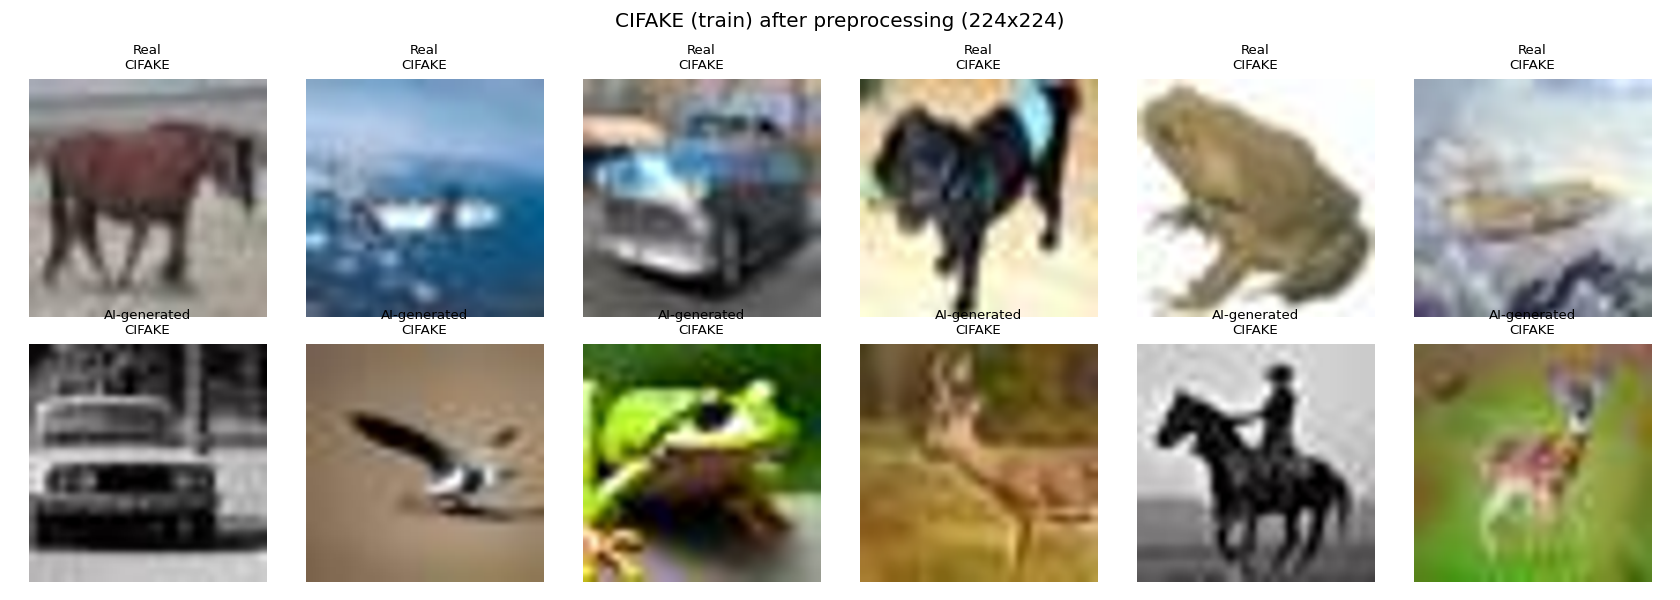

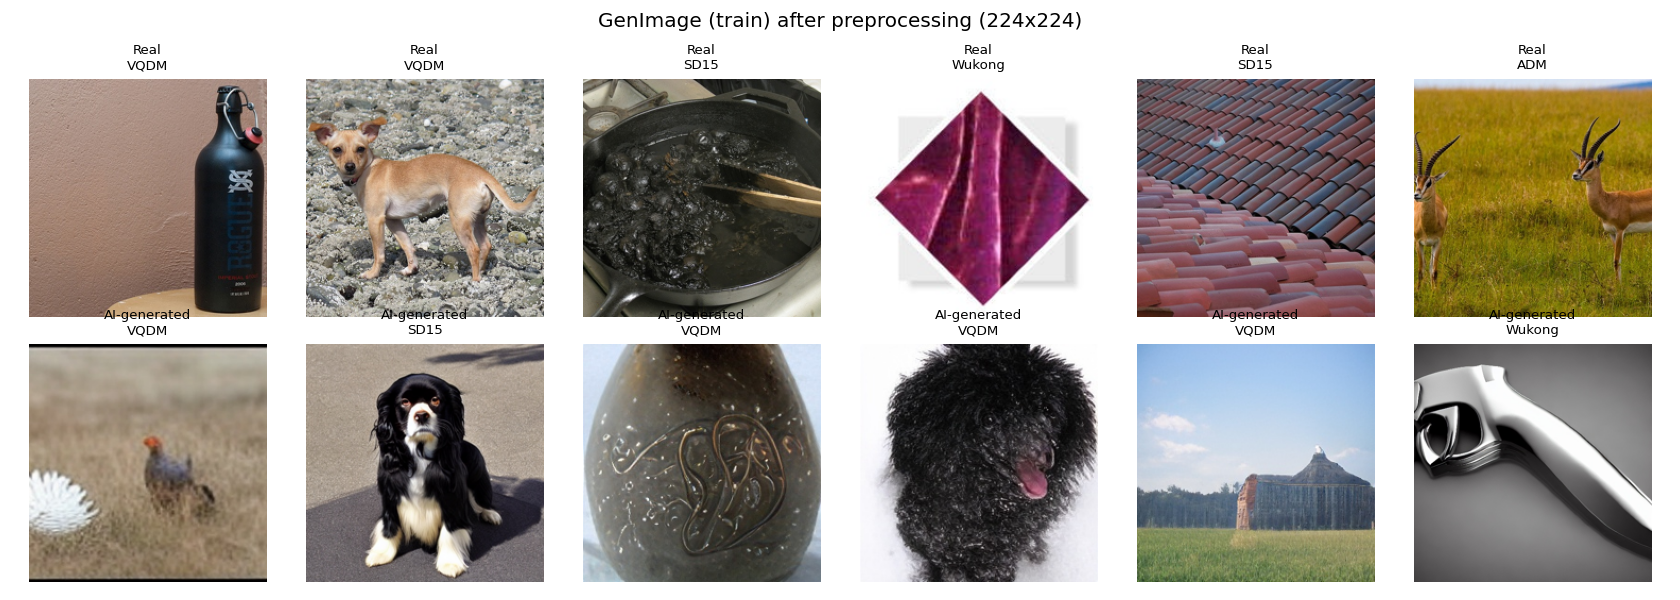

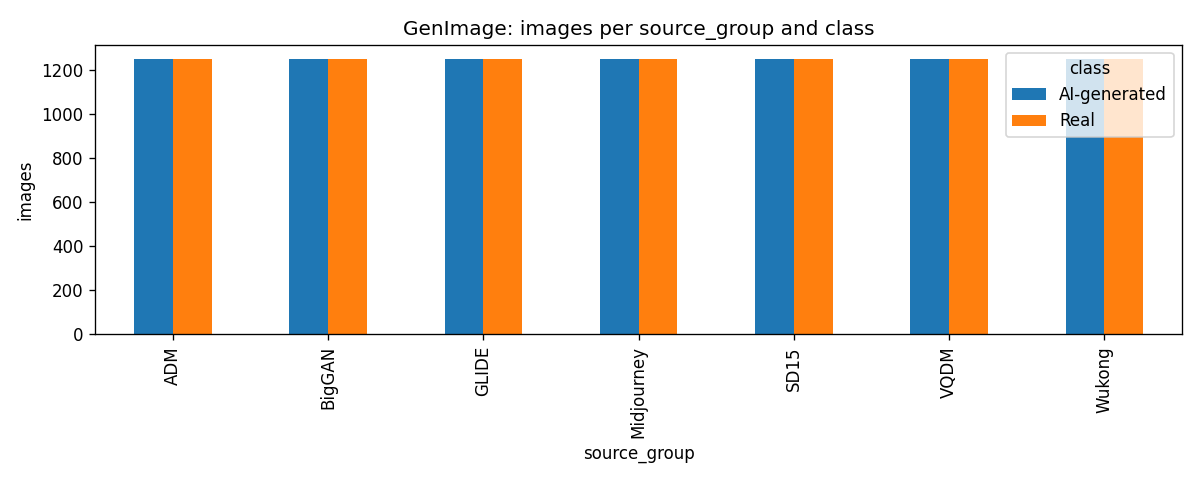

In [39]:
!python -m preprocessing.leakage_audit
!python -m eda.run_eda
from IPython.display import Image, display
for f in ['eda_cifake_samples', 'eda_genimage_samples', 'eda_genimage_counts']:
    display(Image(f'results/figures/{f}.png'))

## <div dir="rtl">الخطوة 8: استخراج الـ features من ResNet50 (تقريبًا 15-25 دقيقة)</div>
<div dir="rtl">هذي الـ features يستخدمها SVM و Random Forest. تنحفظ في درايف.</div>

In [40]:
!python -m features.extract_features

device: cuda
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100% 97.8M/97.8M [00:00<00:00, 125MB/s]
[1/25] extracting CIFAKE/train/clean
   batch 50/438
   batch 100/438
   batch 150/438
   batch 200/438
   batch 250/438
   batch 300/438
   batch 350/438
   batch 400/438
   saved (14000, 2048) in 41s -> CIFAKE_train_clean.npz
[2/25] extracting CIFAKE/val/clean
   batch 50/63
   saved (2000, 2048) in 6s -> CIFAKE_val_clean.npz
[3/25] extracting GenImage/train/clean
   batch 50/313
   batch 100/313
   batch 150/313
   batch 200/313
   batch 250/313
   batch 300/313
   saved (10000, 2048) in 28s -> GenImage_train_clean.npz
[4/25] extracting GenImage/val/clean
   batch 50/79
   saved (2500, 2048) in 7s -> GenImage_val_clean.npz
[5/25] extracting GenImage/train/res32
   batch 50/313
   batch 100/313
   batch 150/313
   batch 200/313
   batch 250/313
   batch 300/313
   saved (10000, 2048) in 35s -> GenImag

## <div dir="rtl">الخطوة 9: SVM (ممكن تاخذ 30-90 دقيقة)</div>
<div dir="rtl">

SVM ما يحتاج GPU. لو تبين توفرين حصة الـ GPU: Runtime ← Change runtime type ← CPU، ثم شغّلي الخطوة 1 وبعدها هذي الخلية (الملفات موجودة في درايف).
لو انقطع الاتصال في النص، شغّليها مرة ثانية: تكمل من آخر إعداد خلص.
</div>

In [4]:
!python -m models.svm_model


=== SVM / cifake: train (14000, 2048), val (2000, 2048) ===
  {"C": 1.0, "gamma": "scale", "kernel": "rbf"}: val AUC=0.9870 acc=0.9430 (194s)
  {"C": 10.0, "gamma": "scale", "kernel": "rbf"}: val AUC=0.9901 acc=0.9510 (200s)
  {"C": 0.01, "kernel": "linear"}: val AUC=0.9822 acc=0.9295 (126s)
  {"C": 0.1, "kernel": "linear"}: val AUC=0.9734 acc=0.9095 (165s)
  BEST (validation): {'C': 10.0, 'gamma': 'scale', 'kernel': 'rbf'}
  saved /content/drive/MyDrive/AI_Image_Detection/checkpoints/svm/svm_cifake.joblib  (val acc 0.9505, AUC 0.9901)

=== SVM / genimage: train (10000, 2048), val (2500, 2048) ===
  {"C": 1.0, "gamma": "scale", "kernel": "rbf"}: val AUC=0.8801 acc=0.8032 (177s)
  {"C": 10.0, "gamma": "scale", "kernel": "rbf"}: val AUC=0.9020 acc=0.8204 (210s)
  {"C": 0.01, "kernel": "linear"}: val AUC=0.8723 acc=0.7936 (143s)
  {"C": 0.1, "kernel": "linear"}: val AUC=0.8523 acc=0.7764 (285s)
  BEST (validation): {'C': 10.0, 'gamma': 'scale', 'kernel': 'rbf'}
  saved /content/drive/MyD

## <div dir="rtl">الخطوة 10: Random Forest (تقريبًا 5-15 دقيقة)</div>

In [5]:
!python -m models.rf_model


=== RF / cifake: train (14000, 2048), val (2000, 2048) ===
  {"max_depth": null, "n_estimators": 200}: val AUC=0.9555 acc=0.8890 (205s)
  {"max_depth": 20, "n_estimators": 200}: val AUC=0.9552 acc=0.8875 (184s)
  {"max_depth": null, "n_estimators": 500}: val AUC=0.9568 acc=0.8905 (507s)
  {"max_depth": 20, "n_estimators": 500}: val AUC=0.9572 acc=0.8925 (462s)
  BEST (validation): {'max_depth': 20, 'n_estimators': 500}
  saved /content/drive/MyDrive/AI_Image_Detection/checkpoints/rf/rf_cifake.joblib  (val acc 0.8925, AUC 0.9572)

=== RF / genimage: train (10000, 2048), val (2500, 2048) ===
  {"max_depth": null, "n_estimators": 200}: val AUC=0.8176 acc=0.7400 (134s)
  {"max_depth": 20, "n_estimators": 200}: val AUC=0.8165 acc=0.7396 (123s)
  {"max_depth": null, "n_estimators": 500}: val AUC=0.8258 acc=0.7452 (331s)
  {"max_depth": 20, "n_estimators": 500}: val AUC=0.8240 acc=0.7400 (308s)
  BEST (validation): {'max_depth': None, 'n_estimators': 500}
  saved /content/drive/MyDrive/AI_Im

## <div dir="rtl">الخطوة 11: تدريب الـ CNN (لازم GPU، تقريبًا 30-60 دقيقة لكل خلية)</div>
<div dir="rtl">ثلاث خلايا: نموذج CIFAKE (تجربة 1 و 3)، نموذج GenImage (تجربة 2)، ونموذج 32×32. شغليها وحدة وحدة.</div>

In [41]:
!python -m training.train_cnn --tag cifake

=== CNN / cifake: CIFAKE (clean), device=cuda, AMP=True ===

--- Stage 1: lr=0.0001, trainable params=2,049 ---
epoch  1 | train loss 0.5764 acc 0.7186 | val loss 0.4824 acc 0.8140 | 43s *best*
epoch  2 | train loss 0.4556 acc 0.8146 | val loss 0.4162 acc 0.8355 | 30s *best*
epoch  3 | train loss 0.4049 acc 0.8345 | val loss 0.3765 acc 0.8505 | 29s *best*
epoch  4 | train loss 0.3762 acc 0.8494 | val loss 0.3555 acc 0.8545 | 29s *best*
epoch  5 | train loss 0.3603 acc 0.8508 | val loss 0.3384 acc 0.8640 | 27s *best*

--- Stage 2: lr=1e-05, trainable params=14,966,785 ---
epoch  6 | train loss 0.2807 acc 0.8813 | val loss 0.1468 acc 0.9440 | 33s *best*
epoch  7 | train loss 0.1326 acc 0.9495 | val loss 0.1176 acc 0.9560 | 34s *best*
epoch  8 | train loss 0.0796 acc 0.9724 | val loss 0.1062 acc 0.9575 | 33s *best*
epoch  9 | train loss 0.0543 acc 0.9806 | val loss 0.0982 acc 0.9625 | 33s *best*
epoch 10 | train loss 0.0368 acc 0.9878 | val loss 0.0857 acc 0.9645 | 33s *best*
epoch 11 | t

In [42]:
!python -m training.train_cnn --tag genimage

=== CNN / genimage: GenImage (clean), device=cuda, AMP=True ===

--- Stage 1: lr=0.0001, trainable params=2,049 ---
epoch  1 | train loss 0.6736 acc 0.5728 | val loss 0.6345 acc 0.6664 | 29s *best*
epoch  2 | train loss 0.6224 acc 0.6628 | val loss 0.6029 acc 0.7036 | 26s *best*
epoch  3 | train loss 0.5957 acc 0.6931 | val loss 0.5878 acc 0.7072 | 22s *best*
epoch  4 | train loss 0.5801 acc 0.7060 | val loss 0.5724 acc 0.7160 | 22s *best*
epoch  5 | train loss 0.5684 acc 0.7138 | val loss 0.5621 acc 0.7316 | 22s *best*

--- Stage 2: lr=1e-05, trainable params=14,966,785 ---
epoch  6 | train loss 0.5154 acc 0.7451 | val loss 0.4524 acc 0.7956 | 25s *best*
epoch  7 | train loss 0.3918 acc 0.8240 | val loss 0.3793 acc 0.8312 | 26s *best*
epoch  8 | train loss 0.2818 acc 0.8840 | val loss 0.3368 acc 0.8544 | 26s *best*
epoch  9 | train loss 0.1898 acc 0.9316 | val loss 0.3226 acc 0.8592 | 26s *best*
epoch 10 | train loss 0.1242 acc 0.9597 | val loss 0.3235 acc 0.8652 | 26s 
epoch 11 | tra

In [44]:
!python -m training.train_cnn --tag res32

cnn_res32.pt exists - skipping (use --force to retrain)


In [45]:
!tail -3 results/tables/cnn_res32_history.csv

11,2,1e-05,0.1815518746137619,0.7485073174476623,0.9437,0.6828,38.3
12,2,1e-05,0.1174747068285942,0.8090777698040008,0.9674,0.6952,40.4
13,2,1e-05,0.07555398625135422,0.8869718741893768,0.9826,0.6944,38.4


## <div dir="rtl">الخطوة 12: تقييم الـ CNN على كل التجارب والـ robustness (تقريبًا 15-25 دقيقة)</div>

In [46]:
!python -m training.eval_cnn

loaded cnn_cifake.pt (best epoch 10, val loss 0.0857)
  exp1   clean      accuracy=0.9590
  exp1   jpeg90     accuracy=0.9567
  exp1   jpeg70     accuracy=0.9530
  exp1   jpeg50     accuracy=0.9473
  exp1   resize112  accuracy=0.9563
  exp1   resize56   accuracy=0.9557
  exp1   noise001   accuracy=0.9032
  exp1   noise003   accuracy=0.7542
  exp1   noise005   accuracy=0.6860
loaded cnn_genimage.pt (best epoch 9, val loss 0.3226)
  exp2   clean      accuracy=0.7814
  exp2   jpeg90     accuracy=0.7640
  exp2   jpeg70     accuracy=0.7314
  exp2   jpeg50     accuracy=0.7008
  exp2   resize112  accuracy=0.6086
  exp2   resize56   accuracy=0.5702
  exp2   noise001   accuracy=0.7212
  exp2   noise003   accuracy=0.5724
  exp2   noise005   accuracy=0.5296
  exp3   clean      accuracy=0.4946
loaded cnn_res32.pt (best epoch 8, val loss 0.5732)
  res32  res32      accuracy=0.6096
saved 91000 predictions -> /content/drive/MyDrive/AI_Image_Detection/results/predictions/cnn_predictions.csv


## <div dir="rtl">الخطوة 13: النتائج النهائية والجداول والرسوم</div>

model experiment     subset  accuracy  precision  recall     f1  roc_auc  balanced_accuracy
  svm       exp1        all    0.9455     0.9464  0.9445 0.9454   0.9883             0.9455
  svm       exp2        all    0.7586     0.7900  0.7044 0.7448   0.8405             0.7586
  svm       exp2     BigGAN    0.8200     0.8101  0.8360 0.8228   0.9037             0.8200
  svm       exp2 Midjourney    0.6972     0.7625  0.5728 0.6542   0.7787             0.6972
  svm       exp3        all    0.6264     0.6224  0.6428 0.6324   0.6573             0.6264
  svm       exp3     BigGAN    0.6428     0.6325  0.6816 0.6561   0.6821             0.6428
  svm       exp3 Midjourney    0.6100     0.6113  0.6040 0.6076   0.6325             0.6100
  svm      res32        all    0.5976     0.6137  0.5268 0.5669   0.6430             0.5976
  svm      res32     BigGAN    0.5916     0.6126  0.4984 0.5496   0.6334             0.5916
  svm      res32 Midjourney    0.6036     0.6147  0.5552 0.5834   0.6530        

,experiment,subset,model,accuracy,precision,recall,f1,roc_auc,balanced_accuracy,n,tn,fp,fn,tp,notes
0,exp1,all,SVM,0.9455,0.9464,0.9445,0.9454,0.9883,0.9455,4000,1893,107,111,1889,NaN
1,exp1,all,Random Forest,0.8892,0.8727,0.9115,0.8917,0.9593,0.8892,4000,1734,266,177,1823,NaN
2,exp1,all,CNN (ResNet50),0.9590,0.9545,0.9640,0.9592,0.9930,0.9590,4000,1908,92,72,1928,NaN
3,exp2,all,SVM,0.7586,0.7900,0.7044,0.7448,0.8405,0.7586,5000,2032,468,739,1761,NaN
4,exp2,BigGAN,SVM,0.8200,0.8101,0.8360,0.8228,0.9037,0.8200,2500,1005,245,205,1045,NaN
5,exp2,Midjourney,SVM,0.6972,0.7625,0.5728,0.6542,0.7787,0.6972,2500,1027,223,534,716,NaN
6,exp2,all,Random Forest,0.7498,0.7310,0.7904,0.7596,0.8309,0.7498,5000,1773,727,524,1976,NaN
7,exp2,BigGAN,Random Forest,0.8240,0.7637,0.9384,0.8421,0.9089,0.8240,2500,887,363,77,1173,NaN
8,exp2,Midjourney,Random Forest,0.6756,0.6881,0.6424,0.6645,0.7480,0.6756,2500,886,364,447,803,NaN
9,exp2,all,CNN (ResNet50),0.7814,0.8125,0.7316,0.7699,0.8609,0.7814,5000,2078,422,671,1829,NaN


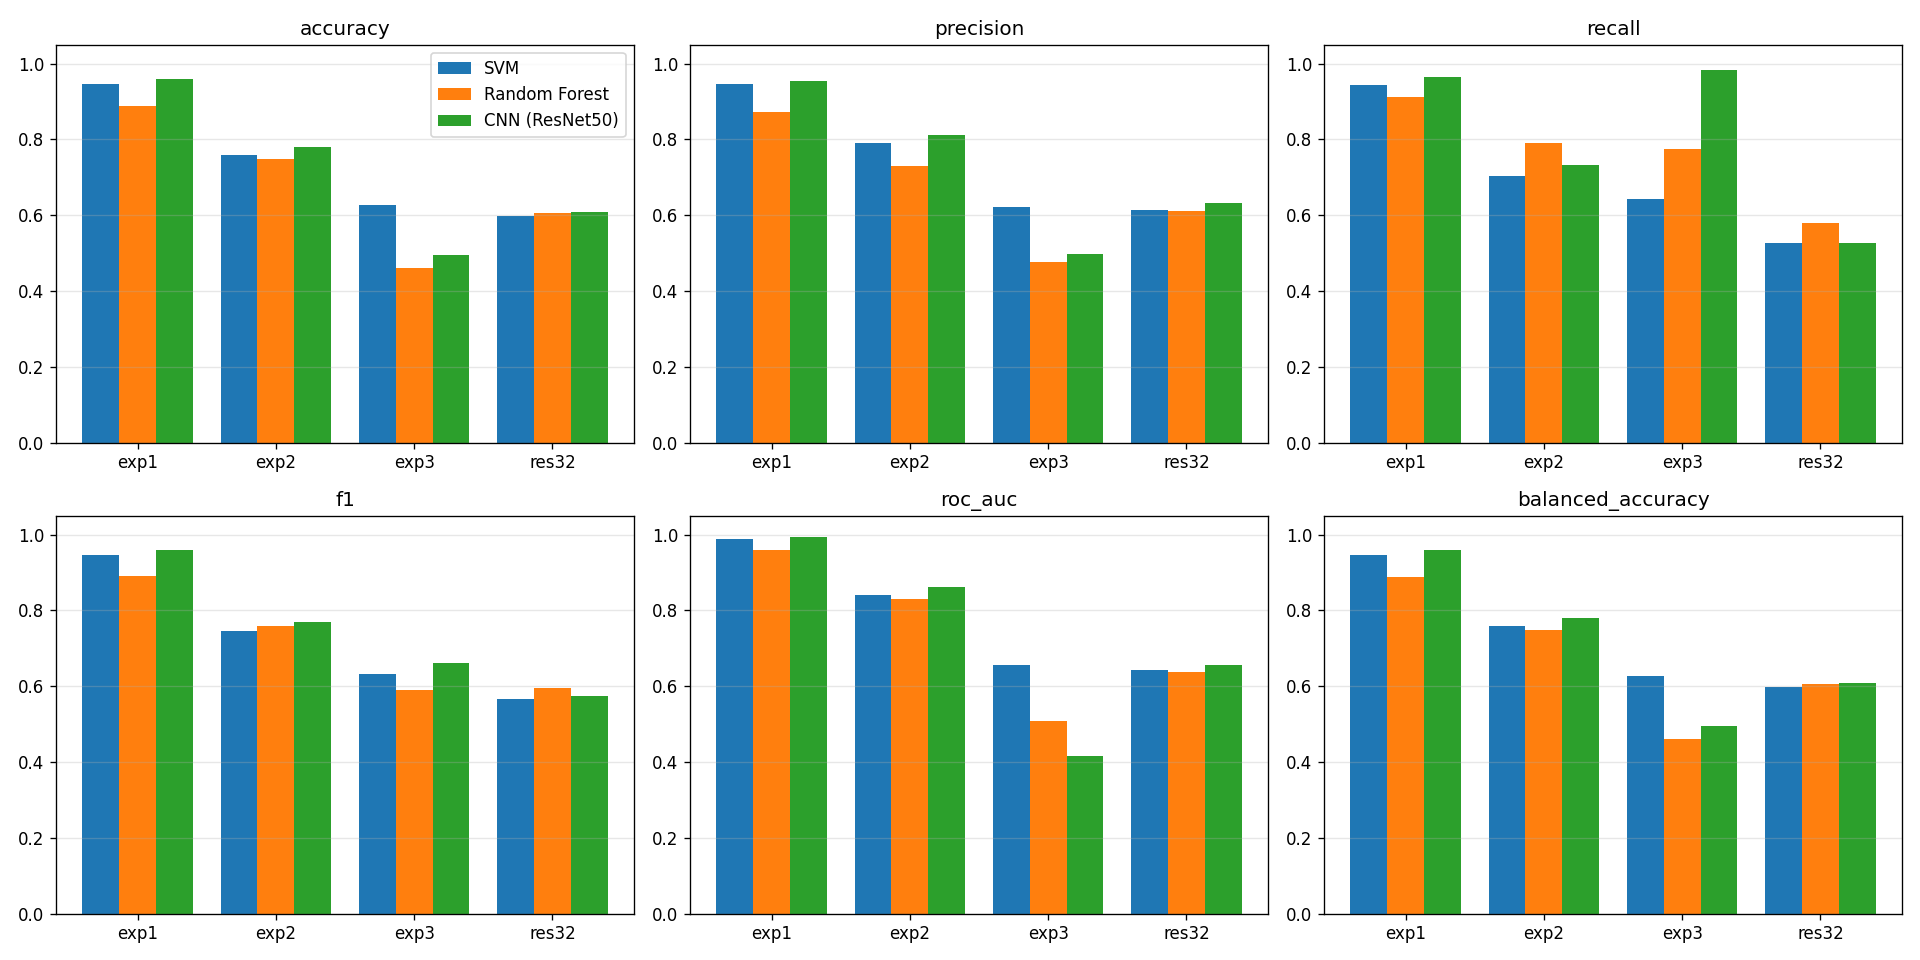

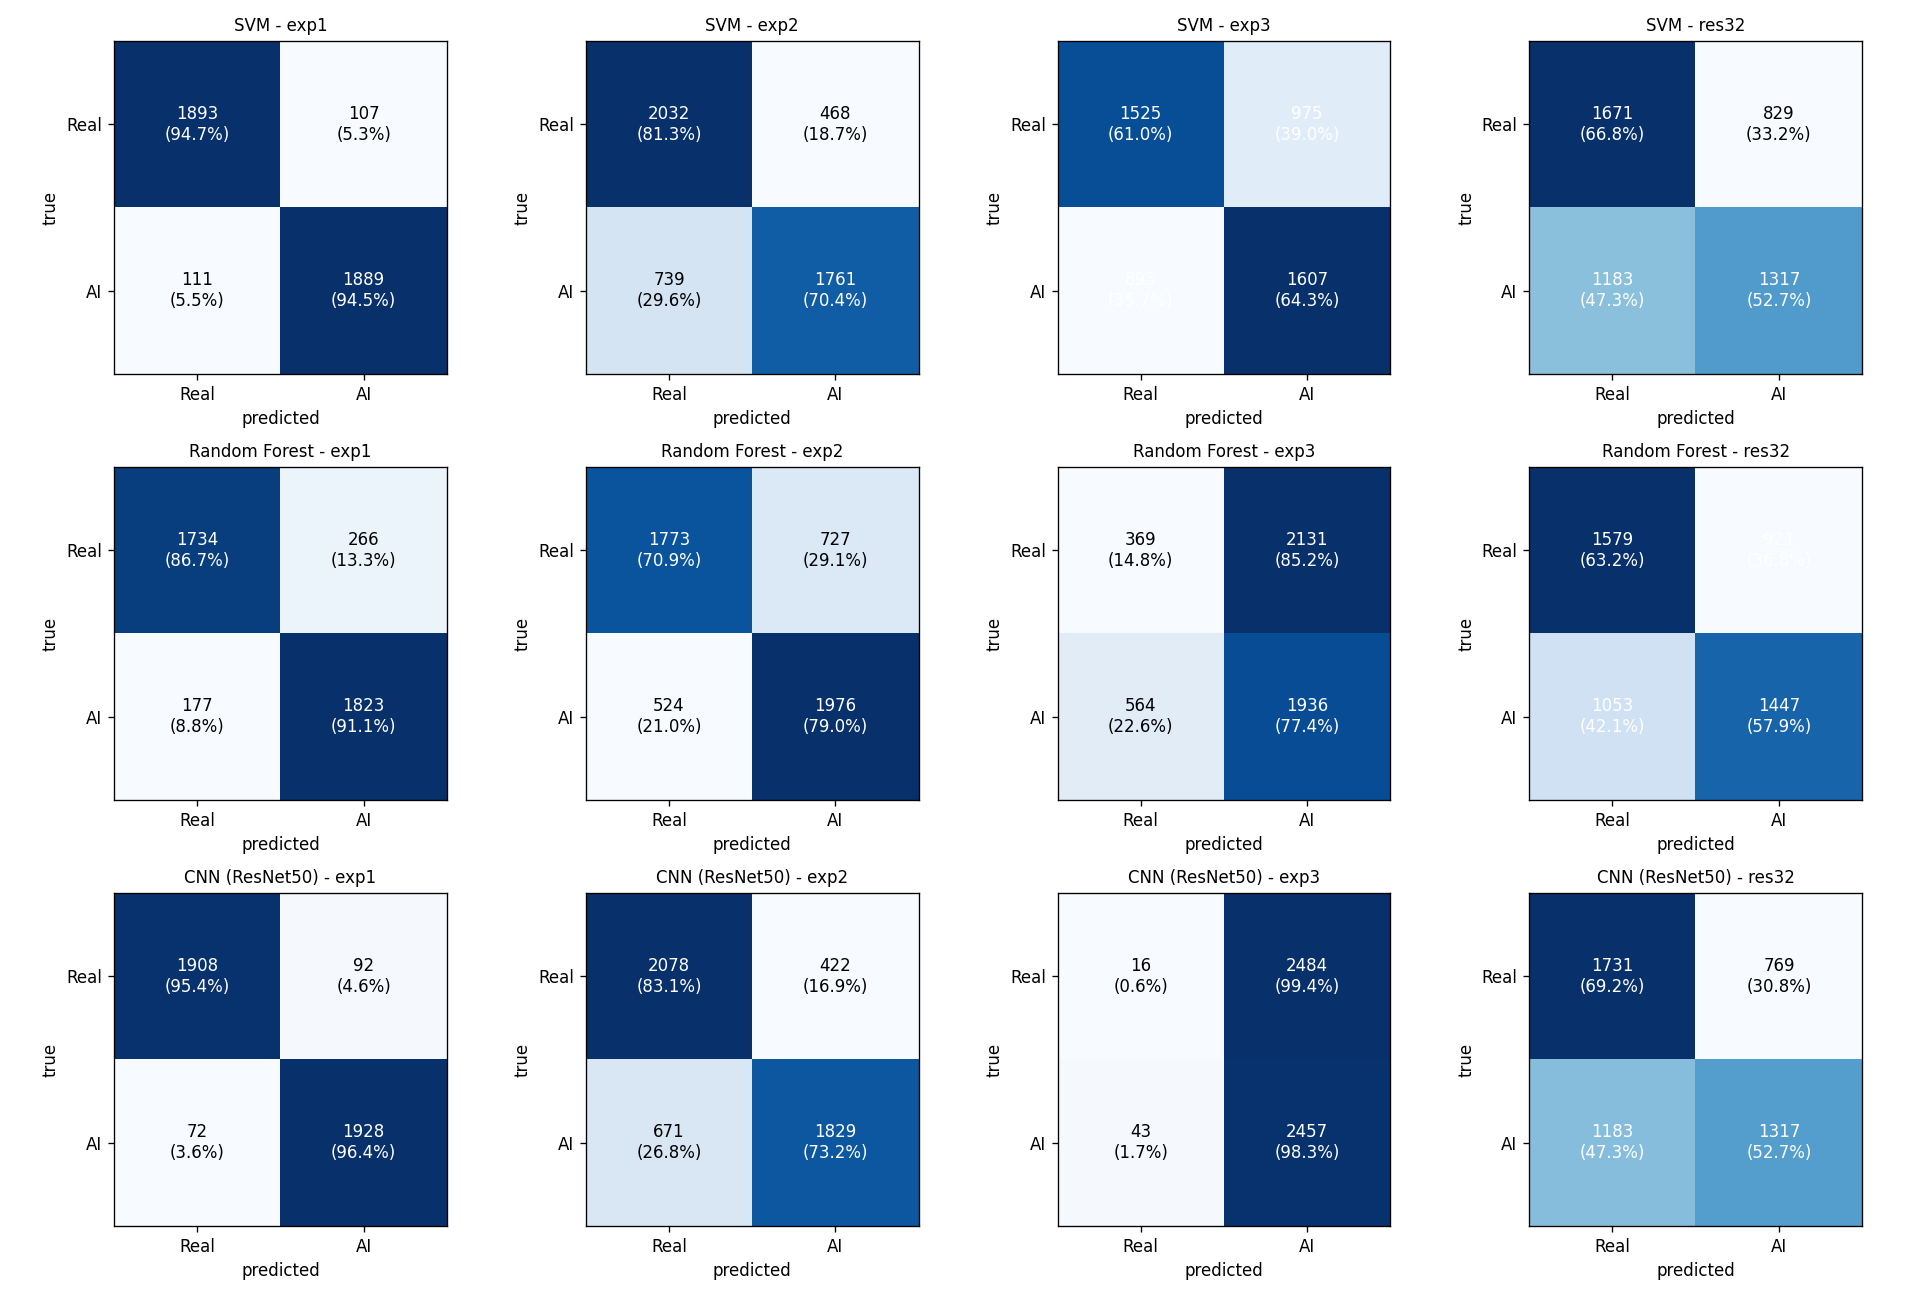

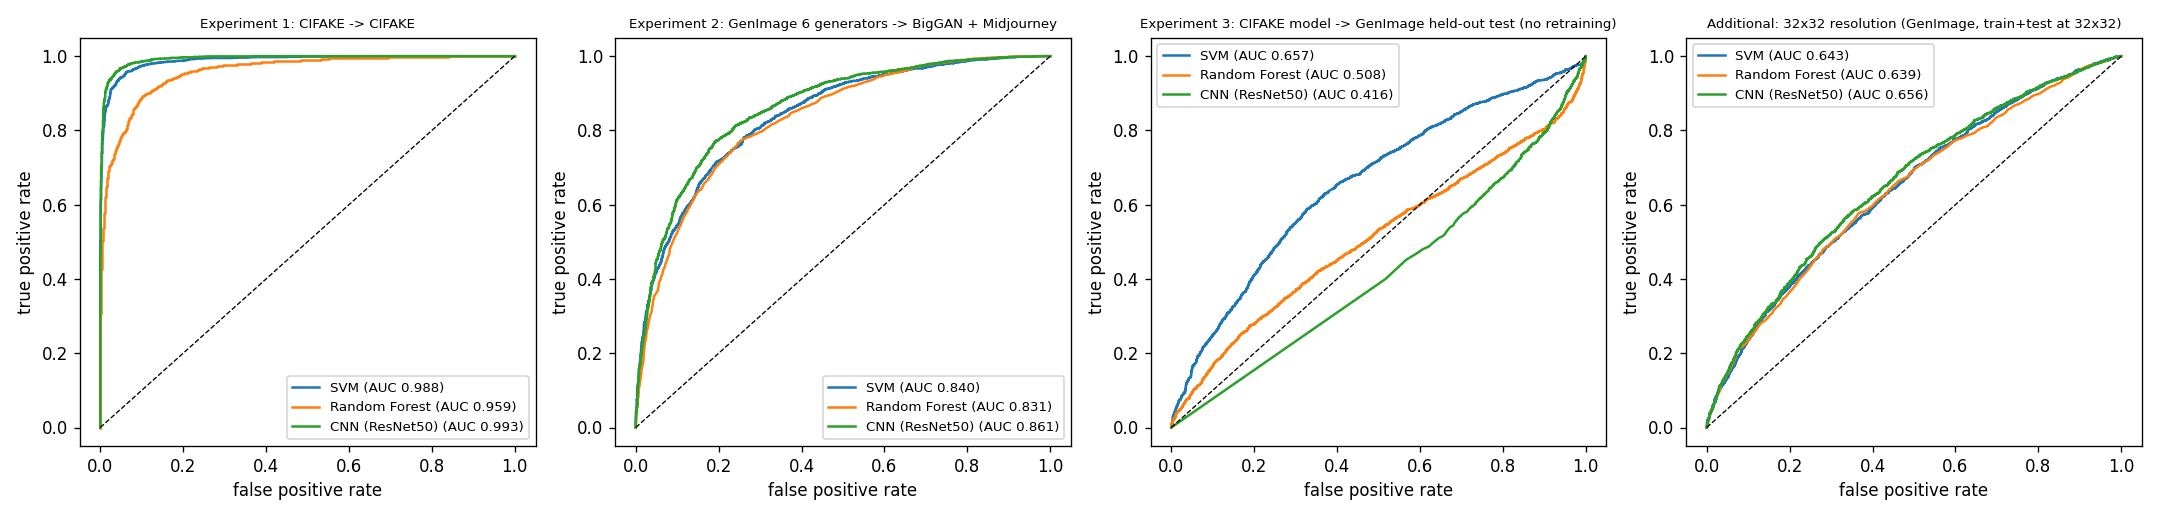

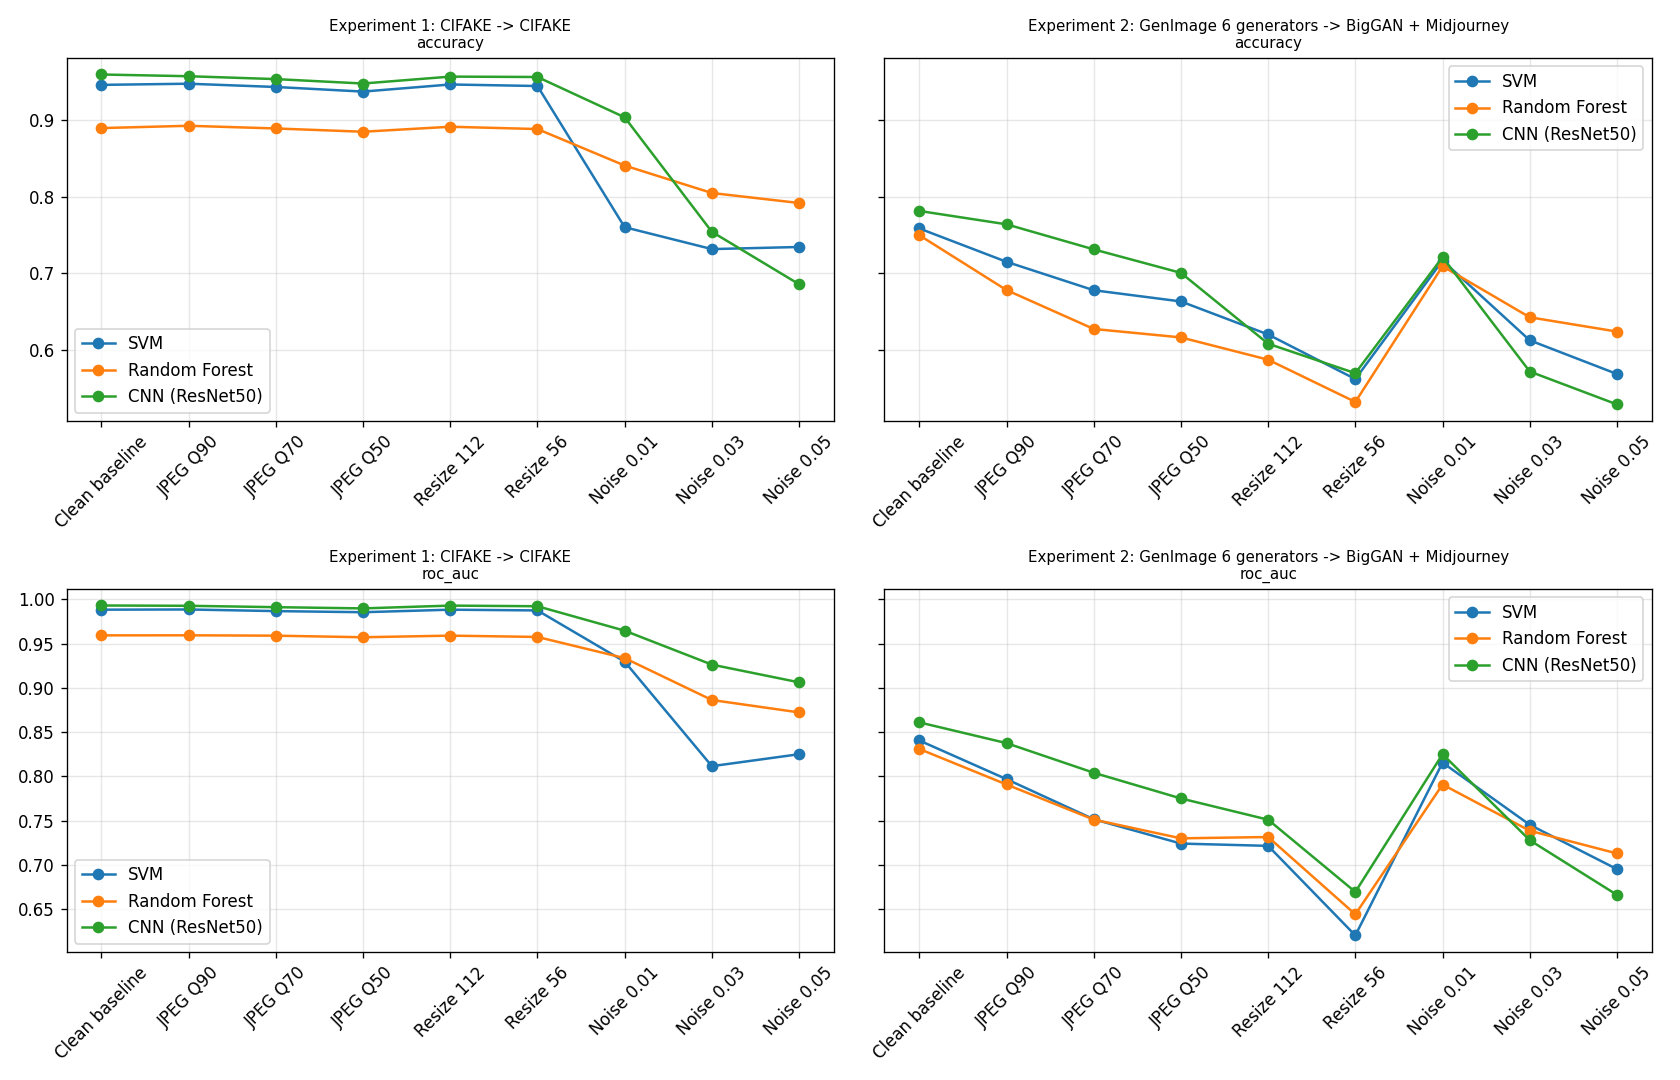

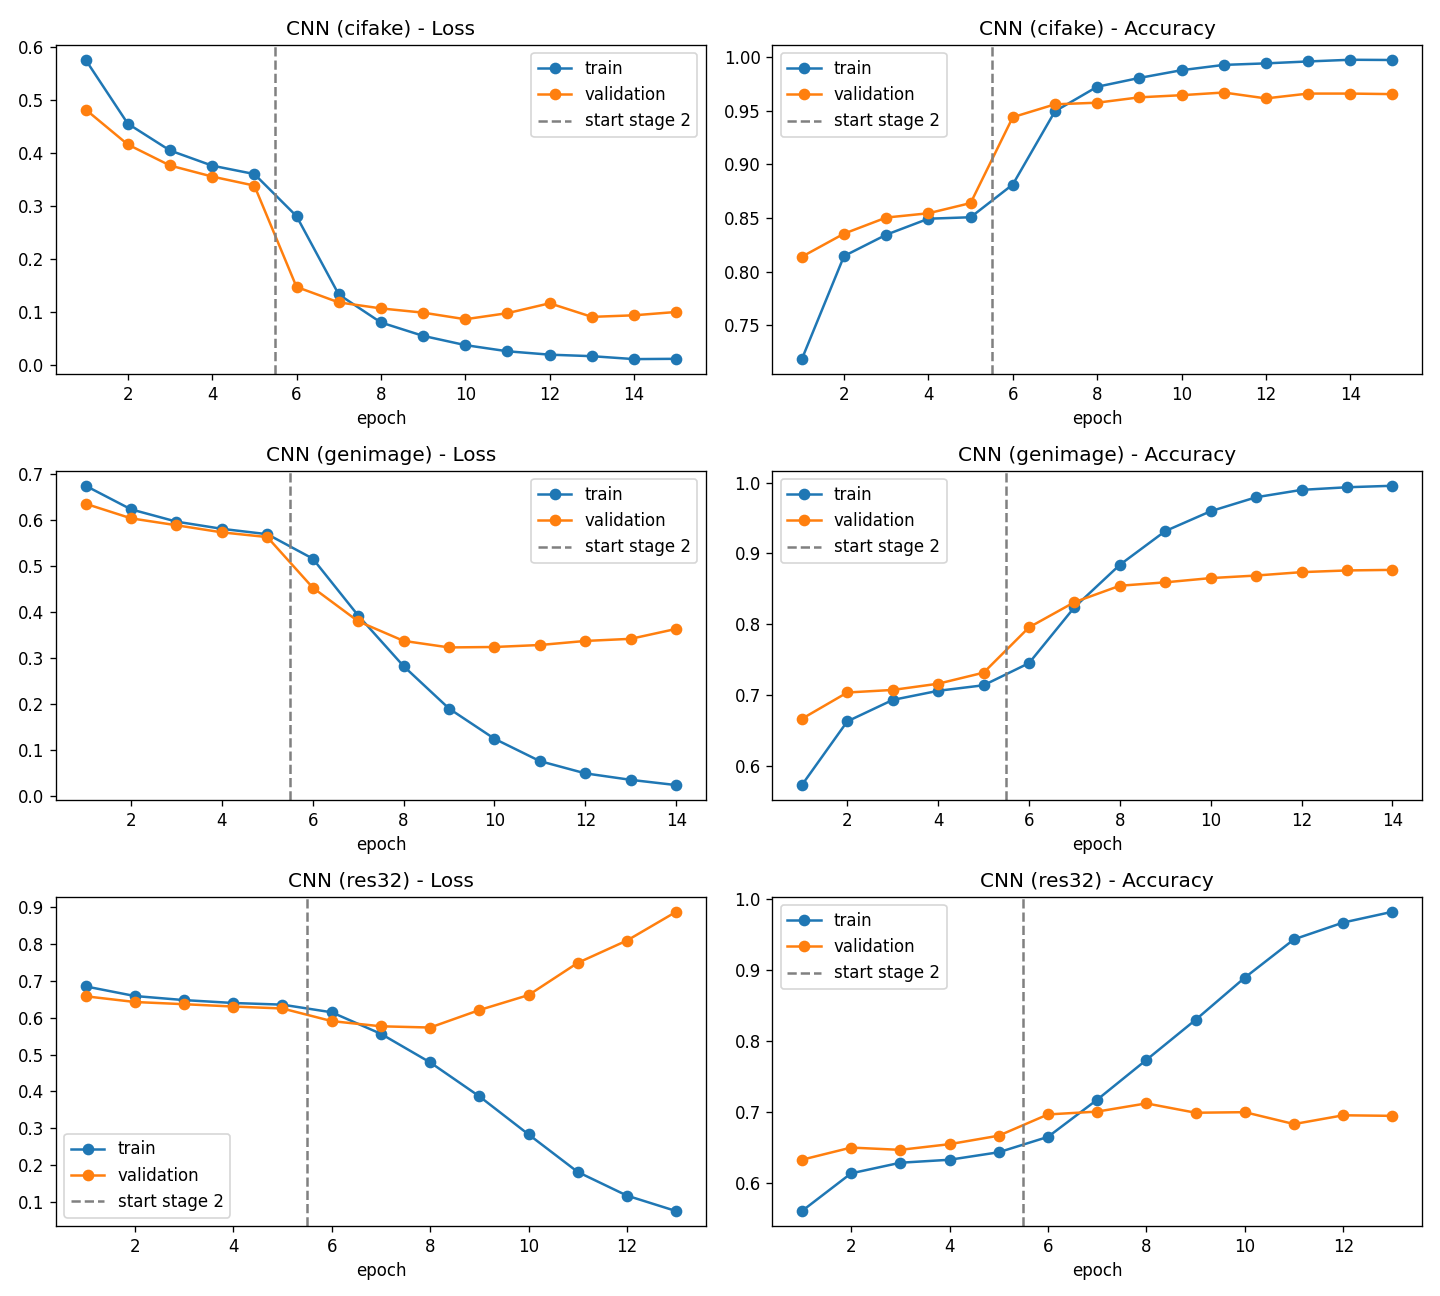

In [6]:
!python -m evaluation.evaluate_models
!python -m evaluation.evaluate_robustness
!python -m evaluation.report_tables
import pandas as pd
from IPython.display import Image, display
display(pd.read_csv('results/tables/final_comparison.csv').round(4))
for f in ['metric_comparison', 'confusion_matrices', 'roc_curves', 'robustness_comparison', 'training_curves']:
    display(Image(f'results/figures/{f}.png'))

In [7]:
import os, pandas as pd
ok = True
def check(name, cond):
    global ok
    print(('✅ PASS  ' if cond else '❌ FAIL  ') + name)
    ok = ok and cond

a = pd.read_csv('data/manifests/leakage_audit.csv')
check('Leakage audit: no FAILED checks', (a['result'] == 'FAIL').sum() == 0)

for m in ['svm', 'rf', 'cnn']:
    p = f'results/predictions/{m}_predictions.csv'
    check(f'{m} predictions exist (91,000 rows)', os.path.exists(p) and len(pd.read_csv(p)) == 91000)

c = pd.read_csv('results/tables/result_completeness.csv')
check('All experiments complete (no MISSING)', (c['status'] == 'MISSING').sum() == 0)

for f in ['svm/svm_cifake.joblib','svm/svm_genimage.joblib','svm/svm_res32.joblib',
          'rf/rf_cifake.joblib','rf/rf_genimage.joblib','rf/rf_res32.joblib',
          'cnn/cnn_cifake.pt','cnn/cnn_genimage.pt','cnn/cnn_res32.pt']:
    check(f'model {f}', os.path.exists(f'checkpoints/{f}'))

for f in ['results/tables/final_comparison.csv','results/robustness/robustness_results.csv',
          'results/final_results_report.md','results/figures/confusion_matrices.png',
          'results/figures/roc_curves.png','results/figures/robustness_comparison.png',
          'results/figures/training_curves.png','results/figures/metric_comparison.png']:
    check(f'output {f}', os.path.exists(f))

print('\n🎉 كل شي يشتغل والمشروع كامل' if ok else '\n⚠️ في شي غلط)

✅ PASS  Leakage audit: no FAILED checks
✅ PASS  svm predictions exist (91,000 rows)
✅ PASS  rf predictions exist (91,000 rows)
✅ PASS  cnn predictions exist (91,000 rows)
✅ PASS  All experiments complete (no MISSING)
✅ PASS  model svm/svm_cifake.joblib
✅ PASS  model svm/svm_genimage.joblib
✅ PASS  model svm/svm_res32.joblib
✅ PASS  model rf/rf_cifake.joblib
✅ PASS  model rf/rf_genimage.joblib
✅ PASS  model rf/rf_res32.joblib
✅ PASS  model cnn/cnn_cifake.pt
✅ PASS  model cnn/cnn_genimage.pt
✅ PASS  model cnn/cnn_res32.pt
✅ PASS  output results/tables/final_comparison.csv
✅ PASS  output results/robustness/robustness_results.csv
✅ PASS  output results/final_results_report.md
✅ PASS  output results/figures/confusion_matrices.png
✅ PASS  output results/figures/roc_curves.png
✅ PASS  output results/figures/robustness_comparison.png
✅ PASS  output results/figures/training_curves.png
✅ PASS  output results/figures/metric_comparison.png

🎉 كل شي يشتغل والمشروع كامل


## <div dir="rtl">الخطوة 14: تحميل النتائج</div>
<div dir="rtl">ينزل لك ملف <code>results.zip</code> فيه كل الجداول والرسوم والتقرير. وكل شي موجود أصلًا في درايف داخل مجلد AI_Image_Detection.</div>

In [ ]:
!zip -qr /content/results.zip results logs data/manifests -x '*.npy'
from google.colab import files
files.download('/content/results.zip')

In [8]:
p = 'README.md'
t = open(p, encoding='utf-8').read()
t = t.replace('| Sample size | 20,000 images per dataset, 50% real / 50% AI |',
 '| Sample size | CIFAKE 20,000; GenImage 17,500 (SD1.4 not available in Tiny-GenImage), 50% real / 50% AI |')
t = t.replace('6 training generators x 2,500 (2,000 train + 500 val)',
 '5 training generators (ADM, GLIDE, SD1.5, VQDM, Wukong) x 2,500 (2,000 train + 500 val); SD1.4 removed - not in the Tiny-GenImage source (team decision)')
t = t.replace('| GenImage: ADM, GLIDE, SD1.4, SD1.5, VQDM, Wukong |', '| GenImage: ADM, GLIDE, SD1.5, VQDM, Wukong |')
open(p, 'w', encoding='utf-8').write(t)
print('README updated' if 'SD1.4 removed' in t else 'NOT updated')

README updated


In [16]:
!zip -qr /content/AI_Image_Detection_submission.zip . -x 'data/cache_backup/*' 'features/saved/*' 'checkpoints/*' '*__pycache__*' '*.ipynb'
!du -h /content/AI_Image_Detection_submission.zip
from google.colab import files
files.download('/content/AI_Image_Detection_submission.zip')

9.3M	/content/AI_Image_Detection_submission.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>